# 1. Project Overview

### Objective

The objective of this practical exercise was to investigate the electricity consumption behaviour of a non-residential building using the Building Data Genome Project 2 (BDG2) dataset.

The analysis focused on understanding temporal patterns, identifying potential operational differences and exploring the underlying components of building electricity readings.

### Selected Building

Building: Panther_office_Karla

Building category: Office

Site: Panther

Floor area: 2,508.4 m²

Study period: January 2016 – December 2017

Data frequency: Hourly

Selected detailed analysis period: January 2017

Import libraries

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [115]:
DATA_PATH = Path(
    r"D:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI"
)

electricity_path = DATA_PATH / "data/meters/raw/electricity.csv"
metadata_path = DATA_PATH / "data/metadata/metadata.csv"
weather_path = DATA_PATH / "data/weather/weather.csv"

In [116]:
electricity = pd.read_csv(electricity_path)
metadata = pd.read_csv(metadata_path)
weather = pd.read_csv(weather_path)

In [117]:
print("Electricity:", electricity.shape)
print("Metadata:", metadata.shape)
print("Weather:", weather.shape)

Electricity: (17544, 1579)
Metadata: (1636, 32)
Weather: (331166, 10)


In [118]:
display(electricity.head())
display(metadata.head())
display(weather.head())

,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


,building_id,site_id,building_id_kaggle,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,...,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
0,Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,...,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
1,Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,...,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
2,Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,...,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN
3,Panther_education_Rosalie,Panther,0.0,0.0,Education,Research,690.5,7432.0,28.517689,-81.379039,...,2008.0,NaN,NaN,NaN,NaN,276,NaN,NaN,NaN,NaN
4,Panther_education_Misty,Panther,1.0,0.0,Education,Research,252.7,2720.0,28.517689,-81.379039,...,2004.0,NaN,NaN,NaN,NaN,375,NaN,NaN,NaN,NaN


,timestamp,site_id,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,precipDepth6HR,seaLvlPressure,windDirection,windSpeed
0,2016-01-01 00:00:00,Panther,19.4,NaN,19.4,0.0,NaN,NaN,0.0,0.0
1,2016-01-01 01:00:00,Panther,21.1,6.0,21.1,-1.0,NaN,1019.4,0.0,0.0
2,2016-01-01 02:00:00,Panther,21.1,NaN,21.1,0.0,NaN,1018.8,210.0,1.5
3,2016-01-01 03:00:00,Panther,20.6,NaN,20.0,0.0,NaN,1018.1,0.0,0.0
4,2016-01-01 04:00:00,Panther,21.1,NaN,20.6,0.0,NaN,1019.0,290.0,1.5


Explore building categories

In [119]:
metadata["primaryspaceusage"].value_counts()

primaryspaceusage
Education                        617
Office                           307
Entertainment/public assembly    204
Lodging/residential              168
Public services                  166
Other                             29
Healthcare                        29
Parking                           24
Warehouse/storage                 15
Manufacturing/industrial          13
Retail                            12
Services                          11
Technology/science                 7
Food sales and service             6
Utility                            4
Religious worship                  3
Name: count, dtype: int64

In [120]:
office_buildings = metadata[
    metadata["primaryspaceusage"] == "Office"
]

display(
    office_buildings[
        ["building_id", "site_id", "sqm", "primaryspaceusage"]
    ].head(10)
)

,building_id,site_id,sqm,primaryspaceusage
5,Panther_office_Daina,Panther,133.8,Office
7,Panther_office_Woodrow,Panther,537.8,Office
16,Panther_office_Karla,Panther,2508.4,Office
23,Panther_office_Graham,Panther,7799.9,Office
25,Panther_office_Valarie,Panther,1416.8,Office
29,Panther_office_Larry,Panther,1738.9,Office
32,Panther_office_Jeane,Panther,654.3,Office
36,Panther_office_Jesus,Panther,9595.6,Office
37,Panther_office_Catherine,Panther,2504.0,Office
40,Panther_office_Garth,Panther,4919.9,Office


In [121]:
electricity.columns[:10]

Index(['timestamp', 'Panther_parking_Lorriane', 'Panther_lodging_Cora',
       'Panther_office_Hannah', 'Panther_lodging_Hattie',
       'Panther_education_Teofila', 'Panther_education_Jerome',
       'Panther_retail_Felix', 'Panther_parking_Asia',
       'Panther_education_Misty'],
      dtype='str')

In [122]:
building_id = "Panther_office_Karla"

if building_id in electricity.columns:
    print("Building meter found!")
else:
    print("Building meter not found!")

Building meter found!


In [123]:
building_data = electricity[
    ["timestamp", building_id]
].copy()

print(building_data.head())
print(building_data.info())

print("Missing values:", building_data[building_id].isna().sum())
print("Zero readings:", (building_data[building_id] == 0).sum())

             timestamp  Panther_office_Karla
0  2016-01-01 00:00:00                   0.0
1  2016-01-01 01:00:00                   0.0
2  2016-01-01 02:00:00                   0.0
3  2016-01-01 03:00:00                   0.0
4  2016-01-01 04:00:00                   0.0
<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             17544 non-null  str    
 1   Panther_office_Karla  17533 non-null  float64
dtypes: float64(1), str(1)
memory usage: 599.8 KB
None
Missing values: 11
Zero readings: 3377


Convert timestamp

In [124]:
building_data["timestamp"] = pd.to_datetime(
    building_data["timestamp"]
)

In [125]:
building_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   timestamp             17544 non-null  datetime64[us]
 1   Panther_office_Karla  17533 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 274.3 KB


In [126]:
building_data = building_data.set_index("timestamp")

In [127]:
building_data

,Panther_office_Karla
timestamp,
2016-01-01 00:00:00,0.0000
2016-01-01 01:00:00,0.0000
2016-01-01 02:00:00,0.0000
2016-01-01 03:00:00,0.0000
2016-01-01 04:00:00,0.0000
...,...
2017-12-31 19:00:00,16.0831
2017-12-31 20:00:00,15.9631
2017-12-31 21:00:00,15.9631


In [128]:
building_data["Panther_office_Karla"].describe()

count    17533.000000
mean        28.549427
std         19.936822
min          0.000000
25%         17.283300
50%         24.124700
75%         44.168500
max        105.140300
Name: Panther_office_Karla, dtype: float64

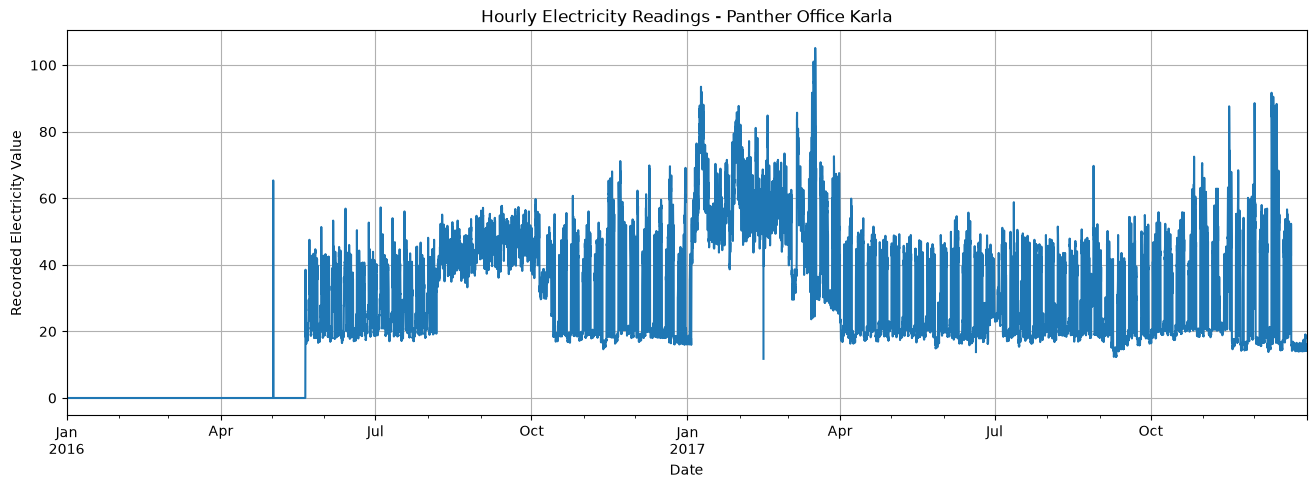

In [129]:
plt.figure(figsize=(16, 5))

building_data["Panther_office_Karla"].plot()

plt.title("Hourly Electricity Readings - Panther Office Karla")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)

plt.show()

Panther Office Karla has distinct changes in electricity consumption across the two-year period.

# Analysis

## Zoom into January 2017

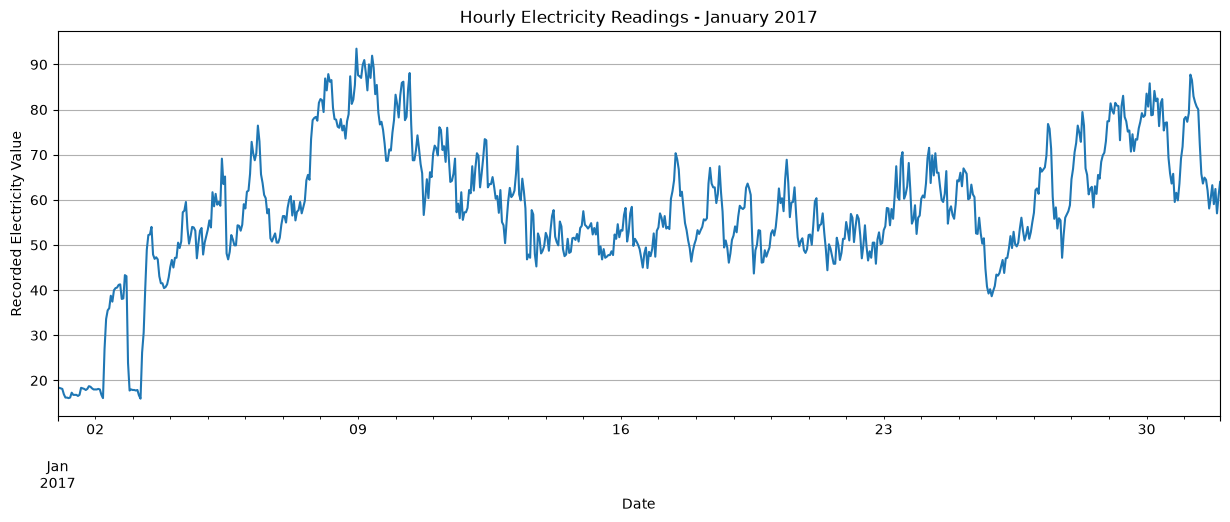

In [130]:
jan_2017 = building_data.loc["2017-01"]

plt.figure(figsize=(15, 5))

jan_2017["Panther_office_Karla"].plot()

plt.title("Hourly Electricity Readings - January 2017")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)

plt.show()

In [131]:
jan_2017["Panther_office_Karla"].describe()

count    744.000000
mean      57.946826
std       15.004943
min       15.963100
25%       50.529700
50%       57.191000
75%       66.462825
max       93.498000
Name: Panther_office_Karla, dtype: float64

the building's electricity readings were substantially higher in January than its overall two-year average.

# Daily energy patterns

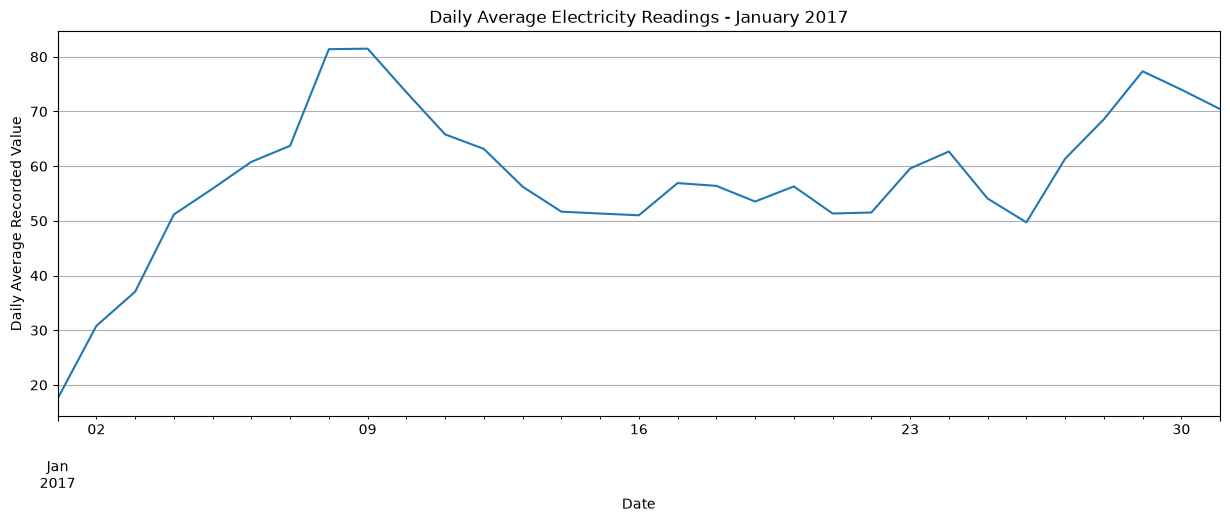

In [132]:
daily_data = building_data[
    "Panther_office_Karla"
].resample("D").mean()

plt.figure(figsize=(15, 5))

daily_data.loc["2017-01"].plot()

plt.title("Daily Average Electricity Readings - January 2017")
plt.xlabel("Date")
plt.ylabel("Daily Average Recorded Value")
plt.grid(True)

plt.show()

The first nine days show a substantial increase, followed by a decline.

This is not necessarily a weekly pattern.

Why?

Because a weekly pattern should repeat approximately every seven days.

# Weekday vs weekend analysis

In [133]:
daily_jan = daily_data.loc["2017-01"].to_frame()

daily_jan["weekday"] = daily_jan.index.day_name()

daily_jan["day_type"] = np.where(
    daily_jan.index.dayofweek < 5,
    "Weekday",
    "Weekend"
)

display(daily_jan.head())

,Panther_office_Karla,weekday,day_type
timestamp,,,
2017-01-01,17.493379,Sunday,Weekend
2017-01-02,30.795942,Monday,Weekday
2017-01-03,37.042146,Tuesday,Weekday
2017-01-04,51.164862,Wednesday,Weekday
2017-01-05,55.890783,Thursday,Weekday


In [134]:
daily_jan.groupby("day_type")[
    "Panther_office_Karla"
].agg(["mean", "median", "std", "count"])

,mean,median,std,count
day_type,,,,
Weekday,58.269199,56.653429,11.391255,22
Weekend,57.158805,51.679971,18.944469,9


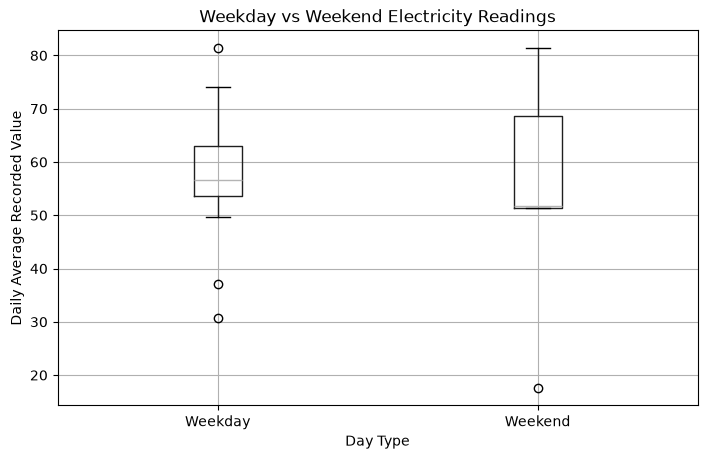

In [135]:
daily_jan.boxplot(
    column="Panther_office_Karla",
    by="day_type",
    figsize=(8, 5)
)

plt.title("Weekday vs Weekend Electricity Readings")
plt.suptitle("")
plt.xlabel("Day Type")
plt.ylabel("Daily Average Recorded Value")
plt.grid(True)

plt.show()

Weekdays
- Median is approximately 56–57.
- Most observations are concentrated around 53–63.
- There are a few unusually low and high observations.

Weekends
- Median is approximately 51–52.
- The box is considerably taller.
- There is greater variation in the middle 50% of observations.
- One unusually low observation appears around 17.

# Hourly Profile Comparison

In [136]:
daily_jan.groupby("day_type")[
    "Panther_office_Karla"
].agg(["count", "mean", "median", "std", "min", "max"])

,count,mean,median,std,min,max
day_type,,,,,,
Weekday,22,58.269199,56.653429,11.391255,30.795942,81.485737
Weekend,9,57.158805,51.679971,18.944469,17.493379,81.390700


In [137]:
hourly_jan = building_data.loc["2017-01"].copy()

hourly_jan["hour"] = hourly_jan.index.hour

hourly_jan["day_type"] = np.where(
    hourly_jan.index.dayofweek < 5,
    "Weekday",
    "Weekend"
)

In [138]:
hourly_profile = hourly_jan.groupby(
    ["day_type", "hour"]
)["Panther_office_Karla"].mean().unstack()

display(hourly_profile)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Weekday,57.163759,58.500382,58.063941,59.569677,61.146350,61.757373,60.900850,62.199291,63.792309,66.809255,...,57.769318,58.140300,57.409264,54.114086,51.920932,53.159359,53.541223,51.097127,52.280991,54.583264
Weekend,57.371078,57.437744,56.330867,59.238100,60.598367,60.478322,58.224567,58.944700,57.997856,57.984511,...,52.810189,54.277156,53.196922,54.957244,56.744278,58.024533,58.664656,59.118078,60.278300,61.878600


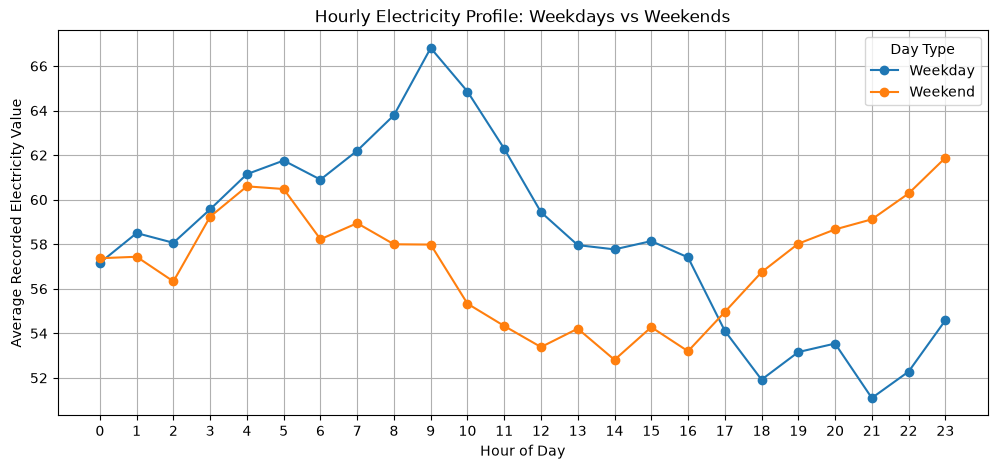

In [139]:
hourly_profile.T.plot(figsize=(12, 5), marker="o")

plt.title("Hourly Electricity Profile: Weekdays vs Weekends")
plt.xlabel("Hour of Day")
plt.ylabel("Average Recorded Electricity Value")
plt.xticks(range(24))
plt.grid(True)
plt.legend(title="Day Type")
plt.show()

Weekday

The building shows a clear increase in recorded electricity readings during the morning, reaching a peak around 9 AM.

Weekend

Readings gradually increase during the evening

# Discover the weekly pattern

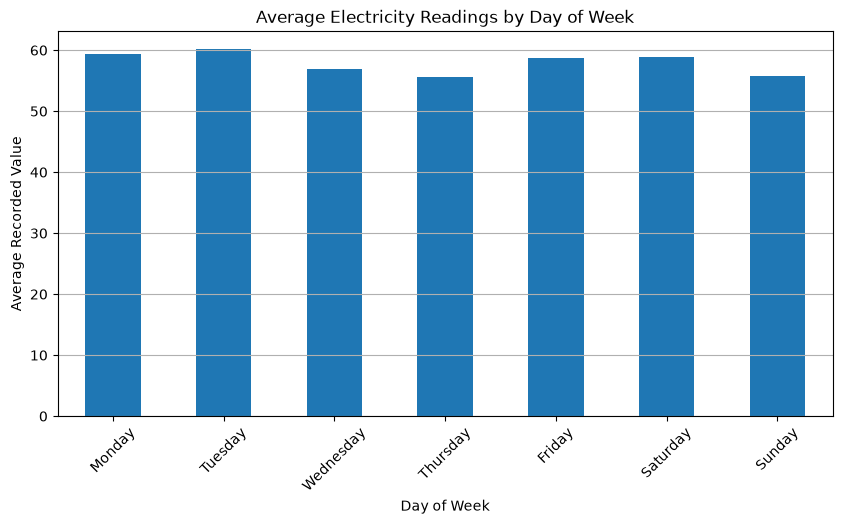

In [140]:
daily_jan["weekday"] = daily_jan.index.day_name()

weekly_profile = daily_jan.groupby(
    "weekday"
)["Panther_office_Karla"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_profile = weekly_profile.reindex(weekday_order)

weekly_profile.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Electricity Readings by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Recorded Value")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

Tuesday has the highest average.

Thursday has the lowest average.

Weekends are not consistently lower.

Differences are relatively small.

# January 2017 investigation.

Monthly statistics - 	Average reading approximately 57.95

Daily profile - 	Significant variation throughout January

Weekday vs weekend - 	Weekdays have a higher median

Hourly profile - 	Different consumption patterns throughout the day

Day-of-week profile - 		Tuesday highest; Thursday lowest

# Time-Series Decomposition

Trend (T): Long-term direction of consumption.
Seasonality (S): Repeating patterns, such as daily or weekly cycles.
Residual (R): Remaining variation that the model cannot explain through trend and seasonality.

In [141]:
jan_hourly = building_data.loc["2017-01", "Panther_office_Karla"]

print(jan_hourly.index.inferred_freq)
print(jan_hourly.isna().sum())

h
0


In [142]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    jan_hourly,
    model="additive",
    period=24
)

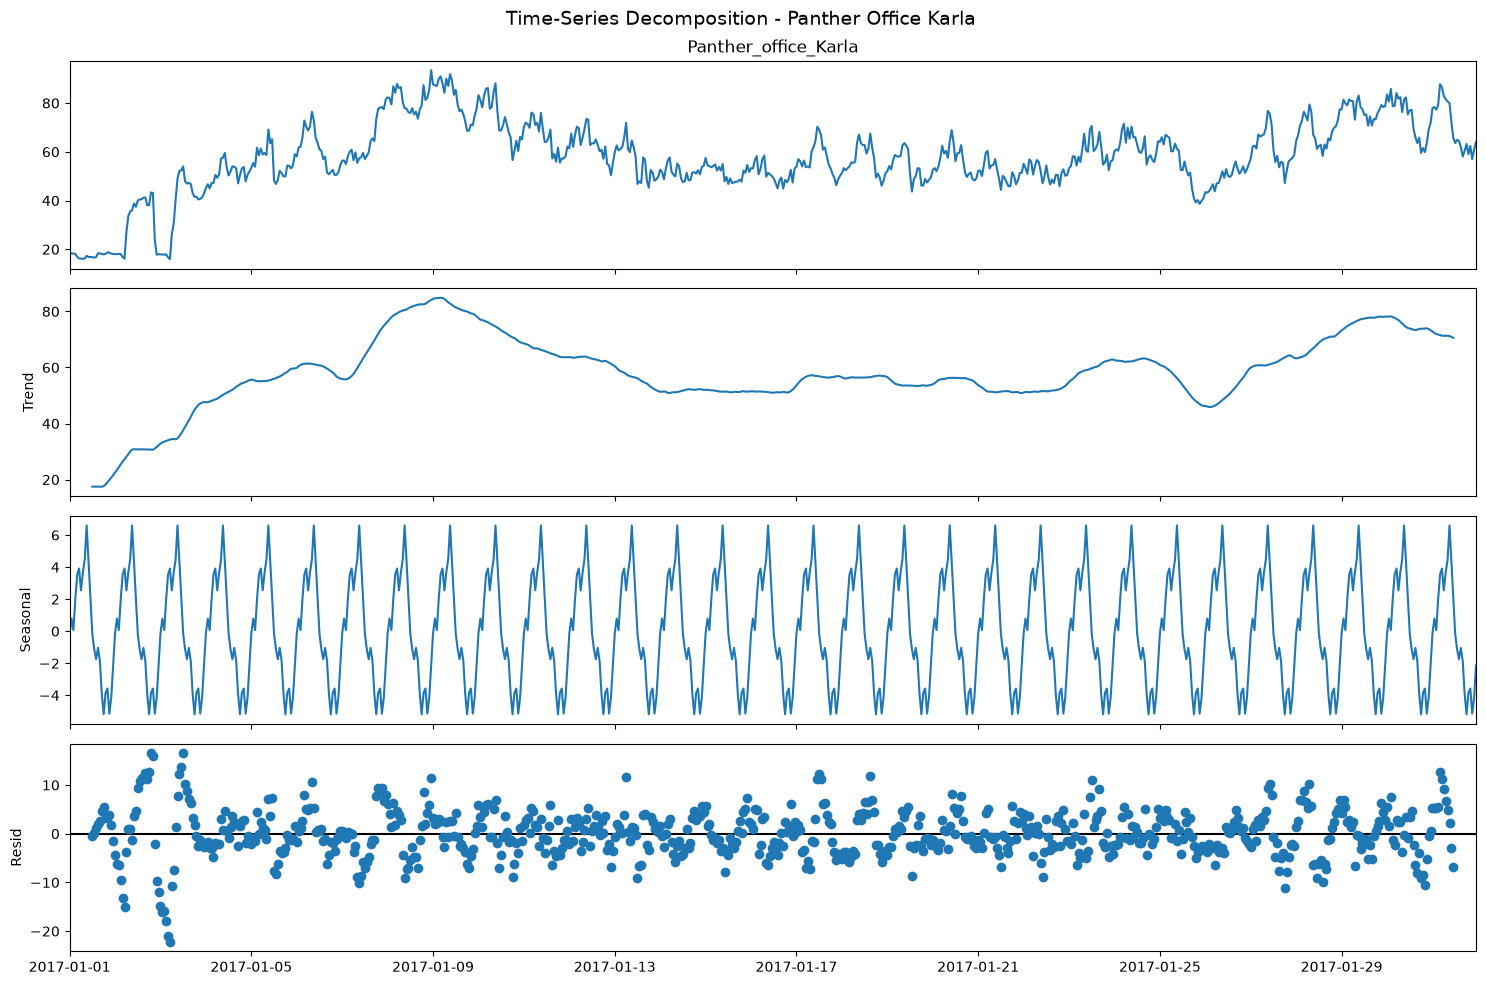

In [143]:
fig = decomposition.plot()

fig.set_size_inches(15, 10)

plt.suptitle(
    "Time-Series Decomposition - Panther Office Karla",
    fontsize=14
)

plt.tight_layout()
plt.show()

Observed	- Electricity readings fluctuate throughout January

Trend	- Underlying reading level changes considerably

Seasonal	- Repeating 24-hour pattern is visible

Residual	- Additional unexplained variation remains

# Investigate weekly seasonality

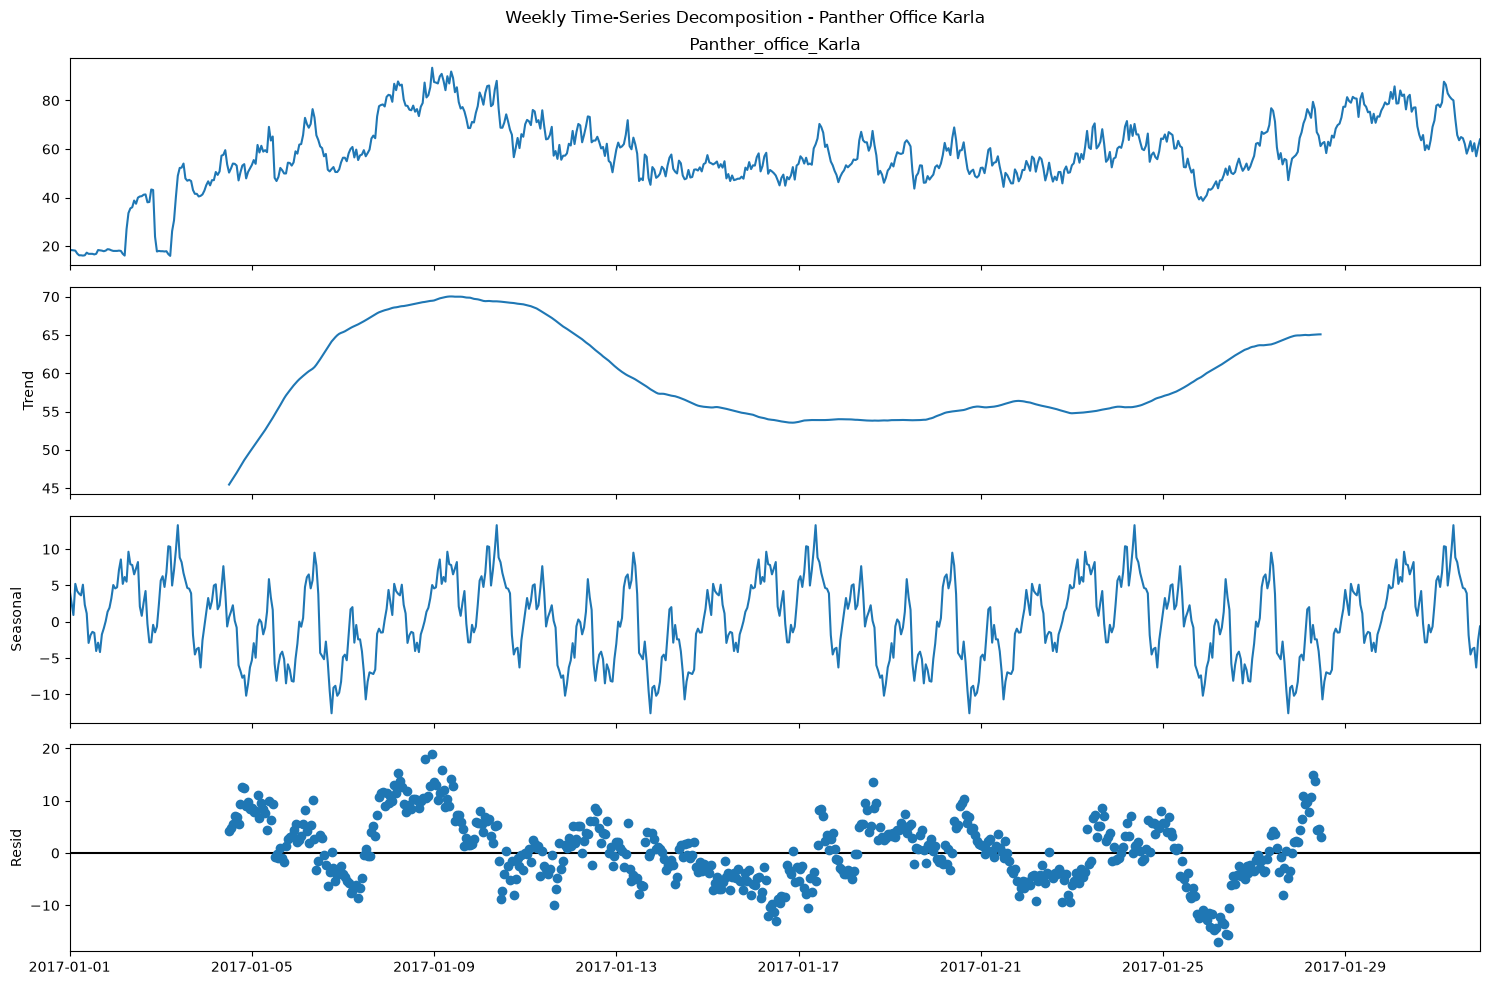

In [144]:
weekly_decomposition = seasonal_decompose(
    jan_hourly,
    model="additive",
    period=168
)

fig = weekly_decomposition.plot()
fig.set_size_inches(15, 10)

plt.suptitle(
    "Weekly Time-Series Decomposition - Panther Office Karla"
)

plt.tight_layout()
plt.show()

# Conclusion

## 2. Dataset Exploration

Three datasets were initially investigated.

| Dataset | Dimensions | Purpose |
|---|---:|---|
| Electricity | 17,544 × 1,579 | Hourly electricity readings from building meters |
| Metadata | 1,636 × 32 | Building characteristics and classifications |
| Weather | 331,166 × 10 | Weather observations |

The electricity dataset follows a wide-format structure:
- Rows represent hourly timestamps.
- Columns represent individual building meters.
- Cells contain recorded electricity values.

The metadata provides building information such as building ID, site, primary space usage and floor area.

The weather dataset contains environmental variables, including air temperature, cloud coverage and precipitation.

These datasets can eventually be connected through timestamps, building IDs and site IDs.

## 3. Building Selection and Data Quality

Panther_office_Karla was selected as the study building.

The building's electricity meter was successfully matched with its metadata record.

### Data Quality Results

| Metric | Result |
|---|---:|
| Total observations | 17,544 |
| Available observations | 17,533 |
| Missing observations | 11 |
| Zero readings | 3,377 |
| Missing data percentage | Approximately 0.063% |
| Zero-reading percentage | Approximately 19.27% |

The timestamp column was converted from string format into Pandas datetime format and subsequently established as the time-series index.

The dataset was confirmed to have hourly sampling frequency.

### Interpretation

The dataset contains very few missing observations but a relatively large number of zero readings.

Missing observations represent unavailable measurements, whereas zero readings are explicitly recorded values.

The zero readings may indicate inactive periods, operational changes or potential meter-data issues. Their actual cause cannot be established from the electricity dataset alone.

Therefore, zero readings were retained rather than automatically treated as missing values.

## 4. Overall Time-Series Analysis

The complete two-year electricity series was visualised to understand its general behaviour.

### Statistical Results

| Statistic | Value |
|---|---:|
| Count | 17,533 |
| Mean | 28.55 |
| Standard deviation | 19.94 |
| Minimum | 0 |
| 25th percentile | 17.28 |
| Median | 24.12 |
| 75th percentile | 44.17 |
| Maximum | 105.14 |

### Observations

1. A prolonged period of zero readings is visible during the initial months of 2016.
2. Non-zero readings become more consistent from approximately June 2016.
3. Higher readings appear during January–March 2017.
4. Consumption readings become relatively stable during parts of the middle of 2017.
5. Higher fluctuations appear again towards the end of 2017.

The mean (28.55) is higher than the median (24.12), indicating that higher readings influence the overall average.

The relatively high standard deviation (19.94) indicates considerable variation across the two-year period.

### Conclusion

The overall time series indicates that the building's recorded electricity behaviour changes considerably over time.

However, the initial zero-reading period influences the overall statistics. Consequently, the two-year average should not be interpreted as a representative operating level without further investigation of the meter's historical data quality.

## 5. January 2017 Statistical Analysis

January 2017 was selected for more detailed investigation because the full-period graph showed higher readings during this period.

### Statistical Results

| Statistic | January 2017 |
|---|---:|
| Count | 744 |
| Mean | 57.95 |
| Standard deviation | 15.00 |
| Minimum | 15.96 |
| Median | 57.19 |
| Maximum | 93.50 |

### Observations

- All 744 hourly observations were available.
- No missing values were detected.
- No zero readings were recorded.
- The mean and median were relatively close.
- The standard deviation was lower than that of the complete two-year dataset.

### Conclusion

January 2017 represents a period of consistently non-zero electricity readings, with a substantially higher average than the full two-year dataset.

The difference suggests a change in the recorded operating conditions of the meter or building.

Possible explanations include occupancy, equipment operation, building systems or changes in meter operation. Further investigation is required before identifying a specific cause.

## 6. Daily Average Analysis

Hourly readings were resampled into daily averages using Pandas resampling.

This reduced the January dataset from 744 hourly observations to 31 daily observations.

### Observations

The daily average graph revealed:

- An increasing trend during the first days of January.
- A high-reading period around January 8–9.
- A gradual decrease towards the middle of the month.
- Relatively stable readings during part of the second half.
- Another increase towards the end of January.

### Conclusion

Daily aggregation makes broader changes in the building's recorded electricity behaviour easier to identify.

However, daily averages can conceal important hourly fluctuations. Therefore, daily and hourly analysis should be used together.

## 7. Weekday vs Weekend Analysis

January 2017 readings were classified into weekdays and weekends.

A box-and-whisker plot was used to compare their statistical distributions.

### Observations

**Weekdays:**
- Median reading was approximately 56–57.
- The middle 50% of observations was relatively concentrated.
- A few potential outliers were identified.

**Weekends:**
- Median reading was approximately 51–52.
- The middle 50% showed greater variability.
- One unusually low observation was visible.

### Conclusion

Weekdays showed a higher median recorded electricity value than weekends.

However, weekend readings demonstrated greater variability.

This suggests that the building's electricity behaviour differs between weekdays and weekends, but the difference is not simply a consistent reduction in weekend readings.

The box plot helped identify differences in central tendency, dispersion and potential outliers.

## 8. Hourly Weekday vs Weekend Profile

Hourly readings were grouped by hour of the day and day type.

The average reading was calculated separately for each hour across weekdays and weekends.

### Weekday Observations

- Readings increased during the early morning.
- A peak appeared around 9 AM, approximately 67.
- Readings gradually declined after the morning peak.
- A further decrease appeared during the evening.

### Weekend Observations

- Morning readings were relatively high.
- Readings generally declined towards midday.
- Lower readings appeared during the afternoon.
- Readings gradually increased during the evening.

### Important Finding

The weekday and weekend profiles showed different hourly behaviour.

For example, around 9 AM, weekday readings were approximately 67, compared with approximately 58 on weekends.

However, around 6 PM, weekend readings were higher than weekday readings.

### Conclusion

The building does not demonstrate a uniform difference between weekday and weekend electricity behaviour throughout the day.

Instead, the timing of electricity demand appears to differ.

This may be associated with operational schedules, occupancy patterns or building-system operation.

Additional occupancy and equipment information would be needed to establish the actual causes.

## 9. Day-of-Week Analysis

Daily averages were grouped into seven categories, from Monday to Sunday.

Approximate observations from the bar chart:

| Day | Average recorded value |
|---|---:|
| Monday | 59.4 |
| Tuesday | 60.1 |
| Wednesday | 56.8 |
| Thursday | 55.5 |
| Friday | 58.8 |
| Saturday | 58.9 |
| Sunday | 55.6 |

### Observations

- Tuesday recorded the highest daily average.
- Thursday recorded the lowest.
- Saturday's average was relatively close to Monday and Friday.
- The difference between the highest and lowest daily averages was relatively small.

### Conclusion

Daily averages were relatively similar across the seven days.

This demonstrates an important distinction: similar daily averages do not necessarily mean that buildings have identical hourly operating patterns.

The hourly profile revealed differences that were less visible in the daily aggregation.

Therefore, analysing data at multiple temporal resolutions provides a more complete understanding of building behaviour.

## 10. Time-Series Decomposition

Classical additive decomposition was performed to separate the electricity readings into three components.

The mathematical representation is:

Y(t) = T(t) + S(t) + R(t)

Where:

- Y(t): Observed electricity reading.
- T(t): Trend component.
- S(t): Seasonal component.
- R(t): Residual component.

### 10.1 Daily Decomposition

A seasonal period of 24 was selected because the dataset contains hourly observations and the objective was to investigate daily repetition.

**Trend:**

The trend showed an increase during the beginning of January, followed by a decrease towards the middle of the month and another increase towards the end.

**Seasonality:**

A repeating 24-hour pattern was visible.

This indicates a recurring daily structure in the recorded electricity readings.

**Residual:**

The residual component fluctuated around zero, with some relatively large positive and negative deviations.

These represent variations not explained by the estimated trend and daily seasonal components.

### 10.2 Weekly Decomposition

A seasonal period of 168 was selected.

168 = 24 hours × 7 days.

This investigated a repeating weekly cycle.

**Trend:**

The trend was smoother than the daily decomposition because of the longer seasonal period.

**Seasonality:**

A repeating weekly seasonal component was generated.

However, the presence of a repeating component alone does not prove that the building has a stable weekly operating pattern.

**Residual:**

The residual component continued to show considerable variation.

### Decomposition Conclusion

The daily decomposition revealed a clear repeating daily structure in the recorded electricity readings.

Weekly decomposition provided an additional way to investigate longer operating cycles.

However, January contains only approximately 4.4 weekly cycles. This is insufficient for a strong conclusion about the stability of weekly seasonality.

A longer observation period is required for more reliable weekly seasonal analysis.

## 11. Overall Research Findings

The exploratory analysis produced five important findings:

**Finding 1 — Temporal variation**

The building's recorded electricity behaviour changed considerably across the two-year observation period.

**Finding 2 — Data quality**

A relatively small number of missing observations was identified, but a substantial number of zero readings requires further investigation.

**Finding 3 — Daily operational patterns**

The hourly profiles revealed recurring daily fluctuations and different weekday/weekend patterns.

**Finding 4 — Temporal aggregation matters**

Daily averages concealed some differences visible in hourly profiles. Analysing different time resolutions provides additional information about building operation.

**Finding 5 — Seasonal structure**

Daily decomposition revealed a repeating 24-hour pattern, while weekly decomposition provided a preliminary investigation of longer operating cycles.

## 12. Final Conclusion

The exploratory time-series analysis of Panther_office_Karla demonstrates how historical electricity readings can be used to investigate the temporal behaviour of a non-residential building.

The analysis identified changes in the underlying reading levels, recurring daily patterns, weekday/weekend differences and unexplained fluctuations.

One of the most important observations is that building electricity behaviour cannot be fully understood through overall averages alone. Hourly profiles, daily aggregation, statistical distributions and time-series decomposition reveal different aspects of operational behaviour.

From an architectural and building-performance perspective, these techniques can support the investigation of operational schedules, energy-demand patterns and potential inefficiencies.

However, the current analysis is exploratory rather than diagnostic. The actual causes of observed changes cannot be established without additional information such as occupancy, HVAC operation, equipment schedules and weather conditions.

### Recommended Next Steps

1. Extend the analysis to the complete two-year dataset.
2. Investigate the initial zero-reading period.
3. Integrate weather data to investigate relationships between outdoor conditions and electricity readings.
4. Perform residual analysis and investigate potential anomalies.
5. Explore forecasting models to predict future electricity readings.
6. Investigate building operational patterns using additional building metadata.

**Overall outcome:** The project establishes a foundation for data-driven building-energy analysis and future AI-based energy forecasting.

# Full-Period Data Quality Analysis

Objective

Before building forecasting or anomaly-detection models, we need to understand whether the complete dataset is reliable.

Remember our earlier finding:
- Total observations: 17,544
- Missing readings: 11
- Zero readings: 3,377
- Zero-reading percentage: 19.27%
The long initial period of zero readings could significantly affect our analysis and future models.

In [145]:
full_series = building_data["Panther_office_Karla"]

monthly_analysis = pd.DataFrame({
    "mean": full_series.resample("ME").mean(),
    "median": full_series.resample("ME").median(),
    "zero_count": full_series.resample("ME").apply(
        lambda x: (x == 0).sum()
    ),
    "missing_count": full_series.resample("ME").apply(
        lambda x: x.isna().sum()
    ),
    "total_readings": full_series.resample("ME").size()
})

monthly_analysis["zero_percentage"] = (
    monthly_analysis["zero_count"] /
    monthly_analysis["total_readings"] * 100
)

display(monthly_analysis.round(2))

,mean,median,zero_count,missing_count,total_readings,zero_percentage
timestamp,,,,,,
2016-01-31,0.00,0.00,744,0,744,100.00
2016-02-29,0.00,0.00,696,0,696,100.00
2016-03-31,0.00,0.00,744,0,744,100.00
2016-04-30,0.00,0.00,720,0,720,100.00
2016-05-31,10.24,0.00,473,0,744,63.58
2016-06-30,29.31,30.25,0,0,720,0.00
2016-07-31,29.06,25.68,0,0,744,0.00
2016-08-31,41.70,42.25,0,0,744,0.00
2016-09-30,47.16,47.05,0,0,720,0.00


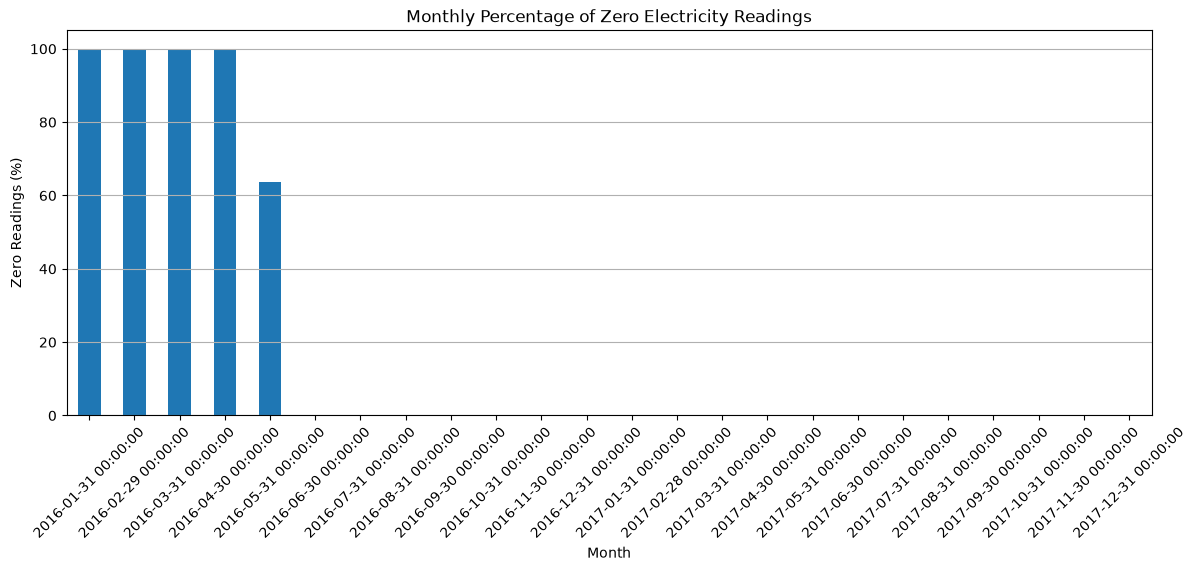

In [146]:
plt.figure(figsize=(14, 5))

monthly_analysis["zero_percentage"].plot(
    kind="bar"
)

plt.title("Monthly Percentage of Zero Electricity Readings")
plt.xlabel("Month")
plt.ylabel("Zero Readings (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

The selected electricity meter exhibits a clear transition from predominantly zero readings to consistent non-zero readings around May–June 2016.

# identify the exact transition date

In [147]:
nonzero_data = full_series[full_series > 0]

print("First non-zero reading:")
print(nonzero_data.index.min())

print("\nLast zero reading:")
print(full_series[full_series == 0].index.max())

First non-zero reading:
2016-05-01 19:00:00

Last zero reading:
2016-05-20 17:00:00


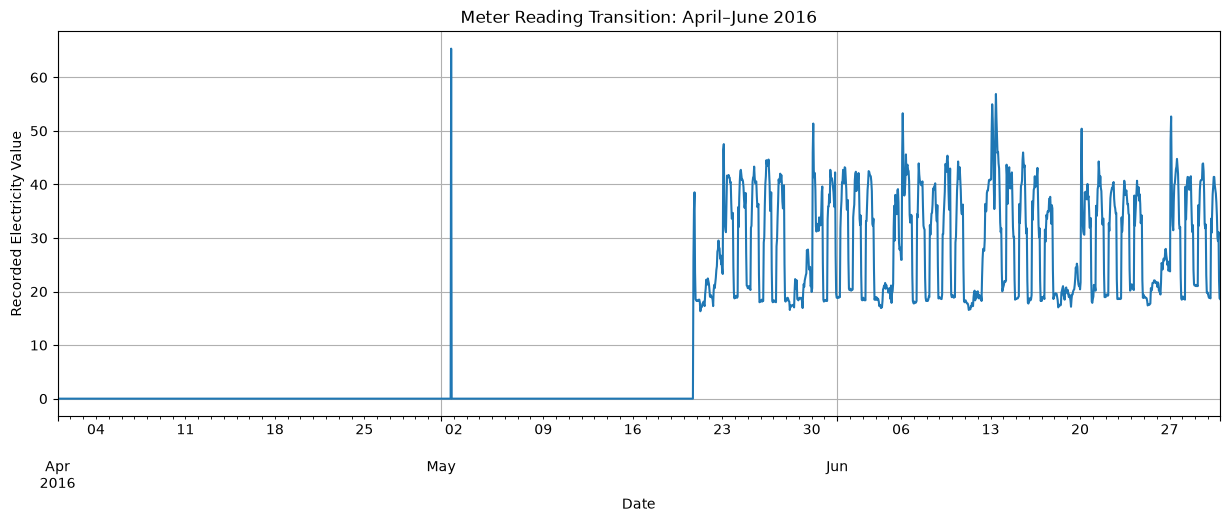

In [148]:
transition_data = full_series.loc[
    "2016-04-01":"2016-06-30"
]

plt.figure(figsize=(15, 5))

transition_data.plot()

plt.title("Meter Reading Transition: April–June 2016")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)

plt.show()

In [149]:
display(monthly_analysis.round(2))

,mean,median,zero_count,missing_count,total_readings,zero_percentage
timestamp,,,,,,
2016-01-31,0.00,0.00,744,0,744,100.00
2016-02-29,0.00,0.00,696,0,696,100.00
2016-03-31,0.00,0.00,744,0,744,100.00
2016-04-30,0.00,0.00,720,0,720,100.00
2016-05-31,10.24,0.00,473,0,744,63.58
2016-06-30,29.31,30.25,0,0,720,0.00
2016-07-31,29.06,25.68,0,0,744,0.00
2016-08-31,41.70,42.25,0,0,744,0.00
2016-09-30,47.16,47.05,0,0,720,0.00


Our preliminary observation is that May 22, 2016 marks the beginning of a sustained non-zero recording pattern.

The investigation of Panther_office_Karla identified a prolonged period of zero electricity readings between January and May 2016. Detailed examination of April–June revealed an isolated non-zero reading on May 2, followed by continued zero readings. A sustained recurring non-zero pattern became visible from approximately May 22, 2016. This suggests a possible transition in meter recording or building operation. Further validation using consecutive non-zero observations is required before defining the operational analysis period.

# Data-quality investigation

The investigation identified 3,377 actual zero readings and 11 missing observations within 17,544 hourly records. The initial period from January to May 2016 contains two prolonged sequences of zero readings. A sustained non-zero recording pattern begins on May 20, 2016. Three subsequent interruptions, totalling 11 hours, were initially classified as zero periods because the Boolean condition full_series > 0 also evaluates to False for missing values. Separating zero readings from missing observations resolved this classification issue.

This demonstrates the importance of distinguishing genuine zero values from missing data during time-series preprocessing.

# Defining the Analysis Period

In [150]:
# Preserve the original data
original_series = full_series.copy()

# Define the provisional analysis period
operational_series = full_series.loc[
    "2016-05-20 18:00:00":
].copy()

print("Original observations:", len(original_series))
print("Analysis observations:", len(operational_series))

print("Positive readings:", (operational_series > 0).sum())
print("Zero readings:", (operational_series == 0).sum())
print("Missing readings:", operational_series.isna().sum())

Original observations: 17544
Analysis observations: 14166
Positive readings: 14155
Zero readings: 0
Missing readings: 11


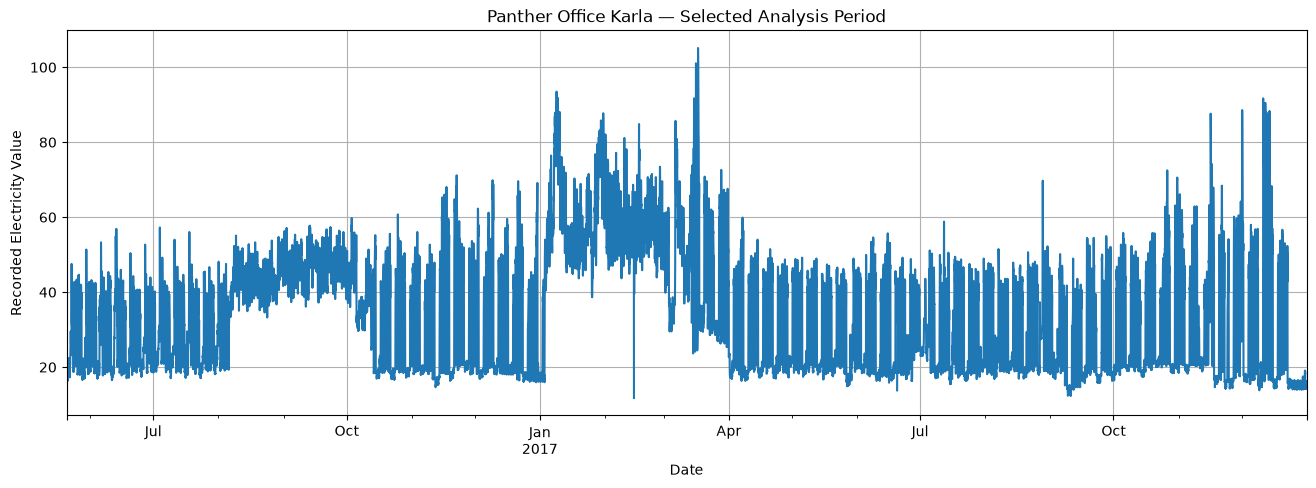

In [151]:
plt.figure(figsize=(16, 5))

operational_series.plot()

plt.title(
    "Panther Office Karla — Selected Analysis Period"
)

plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)

plt.show()

In [152]:
operational_series.describe()

count    14155.000000
mean        35.357948
std         15.856121
min         11.762300
25%         19.683800
50%         35.886900
75%         46.449000
max        105.140300
Name: Panther_office_Karla, dtype: float64

In [153]:
print(
    "Sampling frequency:",
    operational_series.index.inferred_freq
)

Sampling frequency: h


### Selection of the Analysis Period

The initial investigation of Panther_office_Karla identified a prolonged period of zero electricity readings between January and May 2016.

A detailed examination of the April–June 2016 transition revealed an isolated positive reading on May 2, followed by another prolonged sequence of zero readings.

A sustained non-zero recording period began on May 20, 2016, at 18:00.

A seven-day consecutive non-zero threshold was used as an initial screening criterion to distinguish isolated positive observations from sustained recording behaviour.

Therefore, May 20, 2016, at 18:00 was selected as the provisional starting point for the primary operational time-series analysis.

This boundary represents a transition in the recorded meter data and does not establish the actual building activation or occupancy date.

The original dataset is retained for historical reference, while the selected period is used for subsequent exploratory analysis and model development.

# Preparing forecasting data

In [154]:
operational_series

timestamp
2016-05-20 18:00:00    26.1651
2016-05-20 19:00:00    35.4068
2016-05-20 20:00:00    38.5274
2016-05-20 21:00:00    23.6446
2016-05-20 22:00:00    18.6036
                        ...   
2017-12-31 19:00:00    16.0831
2017-12-31 20:00:00    15.9631
2017-12-31 21:00:00    15.9631
2017-12-31 22:00:00    16.2031
2017-12-31 23:00:00    16.0831
Name: Panther_office_Karla, Length: 14166, dtype: float64

In [155]:
target = operational_series.copy()

print(target.head())
print(target.tail())

print("Total observations:", len(target))
print("Missing values:", target.isna().sum())
print("Frequency:", target.index.inferred_freq)

timestamp
2016-05-20 18:00:00    26.1651
2016-05-20 19:00:00    35.4068
2016-05-20 20:00:00    38.5274
2016-05-20 21:00:00    23.6446
2016-05-20 22:00:00    18.6036
Name: Panther_office_Karla, dtype: float64
timestamp
2017-12-31 19:00:00    16.0831
2017-12-31 20:00:00    15.9631
2017-12-31 21:00:00    15.9631
2017-12-31 22:00:00    16.2031
2017-12-31 23:00:00    16.0831
Name: Panther_office_Karla, dtype: float64
Total observations: 14166
Missing values: 11
Frequency: h


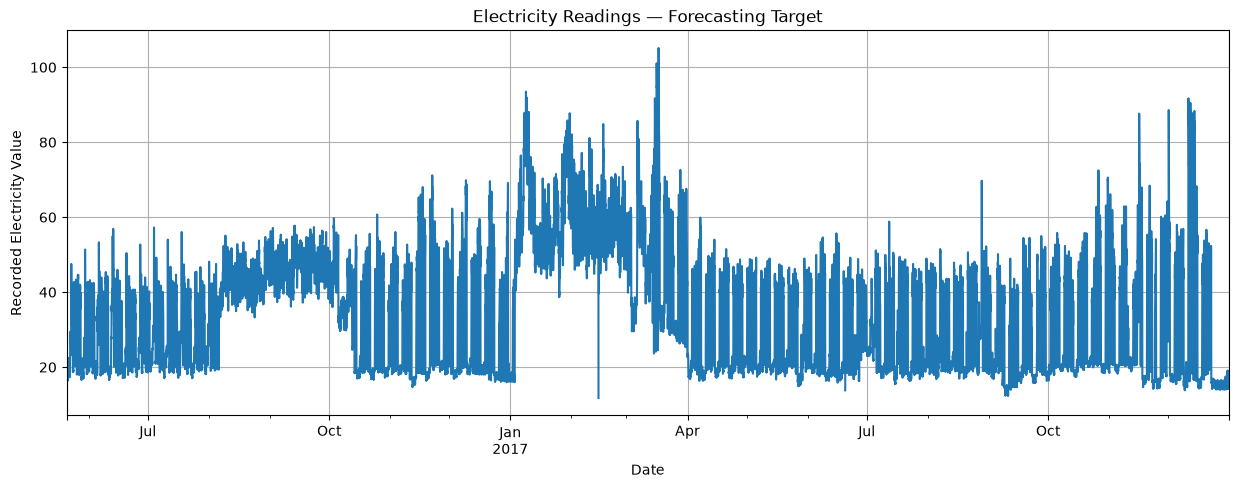

In [156]:
plt.figure(figsize=(15, 5))

target.plot()

plt.title("Electricity Readings — Forecasting Target")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)

plt.show()

# Investigating Missing Values

In [157]:
missing_timestamps = target[target.isna()].index

print("Missing timestamps:")
print(missing_timestamps)

print("\nNumber of missing observations:")
print(len(missing_timestamps))

Missing timestamps:
DatetimeIndex(['2017-02-14 20:00:00', '2017-02-14 21:00:00',
               '2017-02-14 22:00:00', '2017-02-14 23:00:00',
               '2017-03-12 02:00:00', '2017-06-19 19:00:00',
               '2017-06-19 20:00:00', '2017-06-19 21:00:00',
               '2017-06-19 22:00:00', '2017-06-19 23:00:00',
               '2017-06-20 00:00:00'],
              dtype='datetime64[us]', name='timestamp', freq=None)

Number of missing observations:
11


In [158]:
for timestamp in missing_timestamps[:3]:

    print("\nMissing timestamp:", timestamp)

    print(
        target.loc[
            timestamp - pd.Timedelta(hours=2):
            timestamp + pd.Timedelta(hours=2)
        ]
    )


Missing timestamp: 2017-02-14 20:00:00
timestamp
2017-02-14 18:00:00    50.2897
2017-02-14 19:00:00    11.7623
2017-02-14 20:00:00        NaN
2017-02-14 21:00:00        NaN
2017-02-14 22:00:00        NaN
Name: Panther_office_Karla, dtype: float64

Missing timestamp: 2017-02-14 21:00:00
timestamp
2017-02-14 19:00:00    11.7623
2017-02-14 20:00:00        NaN
2017-02-14 21:00:00        NaN
2017-02-14 22:00:00        NaN
2017-02-14 23:00:00        NaN
Name: Panther_office_Karla, dtype: float64

Missing timestamp: 2017-02-14 22:00:00
timestamp
2017-02-14 20:00:00        NaN
2017-02-14 21:00:00        NaN
2017-02-14 22:00:00        NaN
2017-02-14 23:00:00        NaN
2017-02-15 00:00:00    39.7277
Name: Panther_office_Karla, dtype: float64


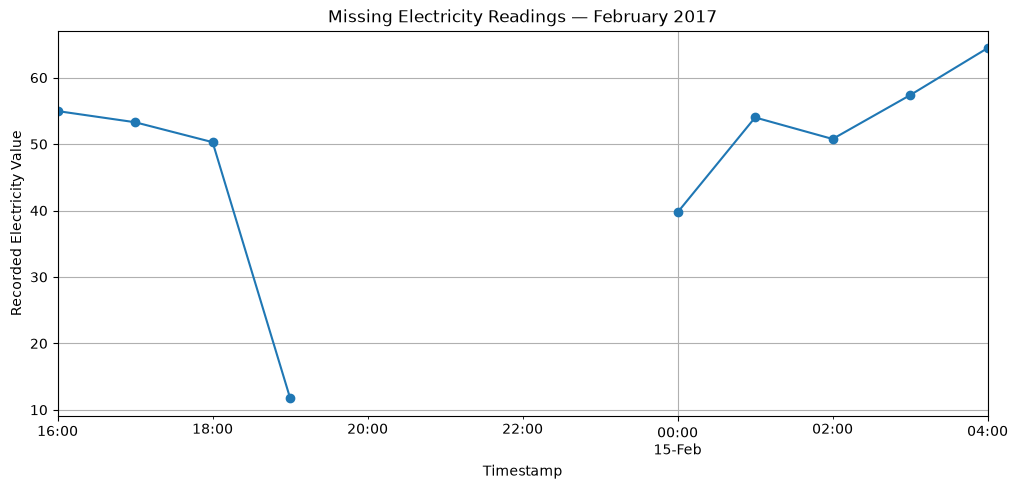

In [159]:
missing_period = target.loc[
    "2017-02-14 16:00:00":
    "2017-02-15 04:00:00"
]

plt.figure(figsize=(12, 5))

missing_period.plot(marker="o")

plt.title("Missing Electricity Readings — February 2017")
plt.xlabel("Timestamp")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)

plt.show()

In [160]:
target_interpolated = target.interpolate(method="time")

In [161]:
print("Missing before:", target.isna().sum())

print("Missing after:", target_interpolated.isna().sum())

Missing before: 11
Missing after: 0


# Chronological Train/Test Split

In [162]:
split_index = int(len(target_interpolated) * 0.8)

train = target_interpolated.iloc[:split_index]

test = target_interpolated.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 11332
Testing observations: 2834
Training period:
2016-05-20 18:00:00 to 2017-09-04 21:00:00

Testing period:
2017-09-04 22:00:00 to 2017-12-31 23:00:00


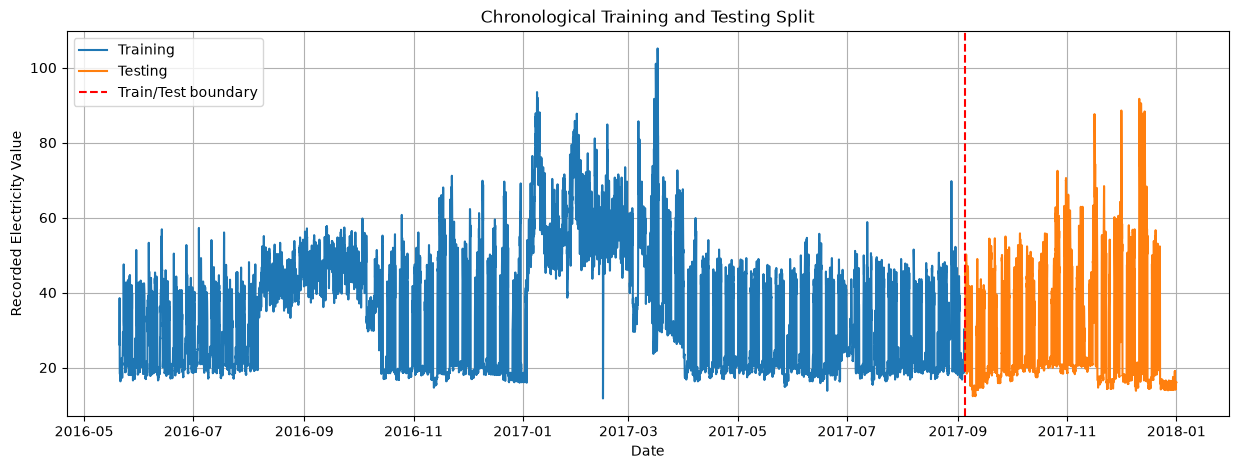

In [163]:
plt.figure(figsize=(15, 5))

plt.plot(train, label="Training")
plt.plot(test, label="Testing")

plt.axvline(
    test.index[0],
    linestyle="--",
    color="red",
    label="Train/Test boundary"
)

plt.title("Chronological Training and Testing Split")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")
plt.legend()
plt.grid(True)

plt.show()

# Model 1 — Naive Forecasting

In [164]:
# Naive forecasting: next reading = previous reading

naive_predictions = target_interpolated.shift(1).loc[test.index]

display(pd.DataFrame({
    "Actual": test.head(10),
    "Predicted": naive_predictions.head(10)
}))

,Actual,Predicted
timestamp,,
2017-09-04 22:00:00,21.9642,22.8044
2017-09-04 23:00:00,21.9642,21.9642
2017-09-05 00:00:00,22.8044,21.9642
2017-09-05 01:00:00,20.8840,22.8044
2017-09-05 02:00:00,21.0040,20.8840
2017-09-05 03:00:00,20.6440,21.0040
2017-09-05 04:00:00,20.5240,20.6440
2017-09-05 05:00:00,21.0040,20.5240
2017-09-05 06:00:00,43.9285,21.0040


In [165]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Keep only genuinely observed test values.
valid_mask = target.loc[test.index].notna()

actual = target.loc[test.index][valid_mask]
predicted = naive_predictions[valid_mask]

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("Naive Forecast Results")
print("----------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

Naive Forecast Results
----------------------
MAE: 2.553
RMSE: 5.523


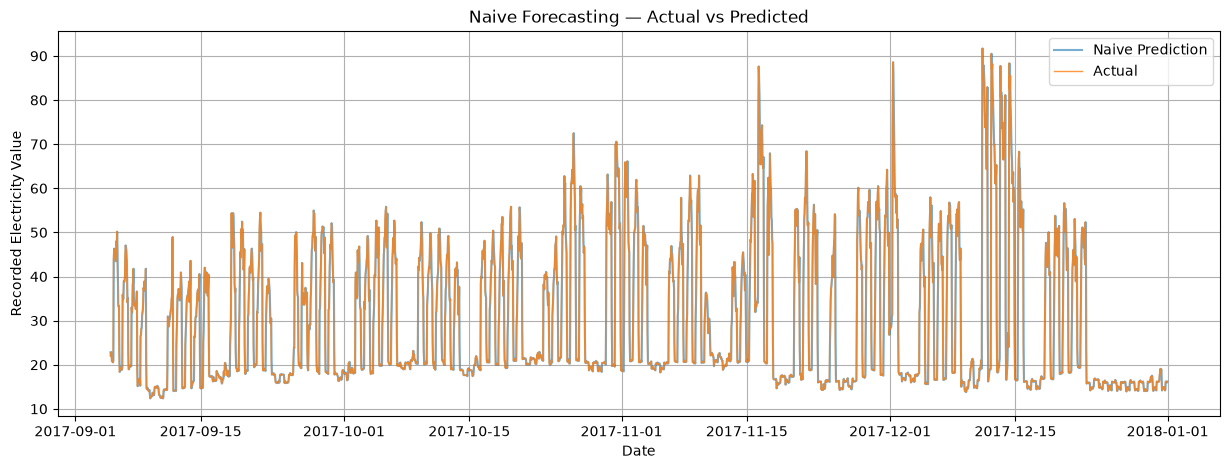

In [166]:
plt.figure(figsize=(15, 5))

plt.plot(
    predicted.index,
    predicted,
    label="Naive Prediction",
    alpha=0.6,
    linewidth=1.5
)

plt.plot(
    actual.index,
    actual,
    label="Actual",
    alpha=0.8,
    linewidth=1
)

plt.title("Naive Forecasting — Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")

plt.legend()
plt.grid(True)
plt.show()

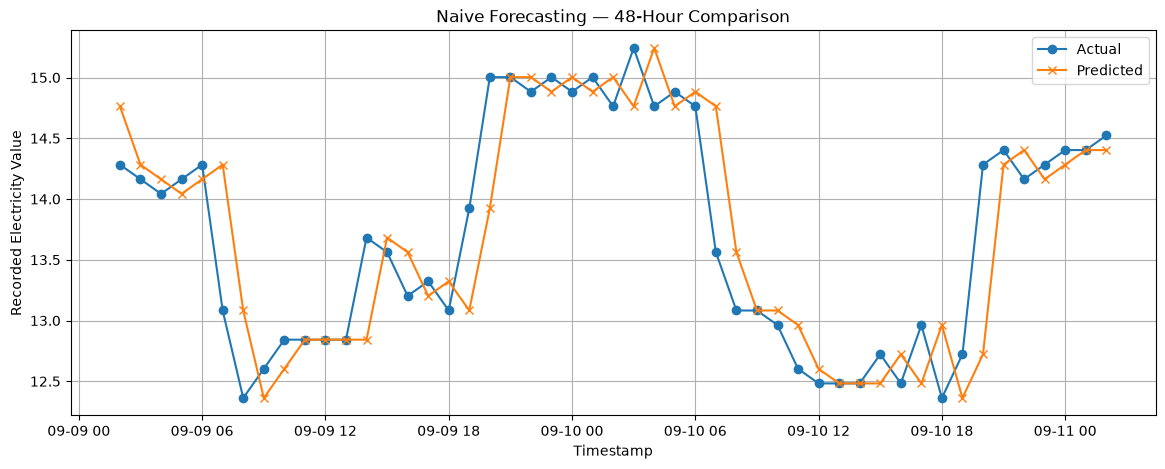

In [167]:
zoom_start = actual.index[100]

zoom_end = zoom_start + pd.Timedelta(hours=48)

plt.figure(figsize=(14, 5))

plt.plot(
    actual.loc[zoom_start:zoom_end],
    label="Actual",
    marker="o"
)

plt.plot(
    predicted.loc[zoom_start:zoom_end],
    label="Predicted",
    marker="x"
)

plt.title("Naive Forecasting — 48-Hour Comparison")
plt.xlabel("Timestamp")
plt.ylabel("Recorded Electricity Value")

plt.legend()
plt.grid(True)
plt.show()

# Seasonal Naive Forecasting

In [168]:
# Seasonal Naive: use the reading from 24 hours earlier

seasonal_predictions = (
    target_interpolated.shift(24).loc[test.index]
)

display(pd.DataFrame({
    "Actual": test.head(10),
    "Naive": naive_predictions.head(10),
    "Seasonal Naive": seasonal_predictions.head(10)
}))

,Actual,Naive,Seasonal Naive
timestamp,,,
2017-09-04 22:00:00,21.9642,22.8044,21.0040
2017-09-04 23:00:00,21.9642,21.9642,19.9238
2017-09-05 00:00:00,22.8044,21.9642,20.2839
2017-09-05 01:00:00,20.8840,22.8044,19.3237
2017-09-05 02:00:00,21.0040,20.8840,19.8038
2017-09-05 03:00:00,20.6440,21.0040,19.6838
2017-09-05 04:00:00,20.5240,20.6440,19.8038
2017-09-05 05:00:00,21.0040,20.5240,18.8436
2017-09-05 06:00:00,43.9285,21.0040,19.6838


In [169]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Evaluate only genuine observations
valid_mask = target.loc[test.index].notna()

actual = target.loc[test.index][valid_mask]

seasonal_pred = seasonal_predictions[valid_mask]

seasonal_mae = mean_absolute_error(
    actual, seasonal_pred
)

seasonal_rmse = np.sqrt(
    mean_squared_error(actual, seasonal_pred)
)

print("Seasonal Naive Results")
print("----------------------")
print("MAE:", round(seasonal_mae, 3))
print("RMSE:", round(seasonal_rmse, 3))

Seasonal Naive Results
----------------------
MAE: 7.521
RMSE: 13.694


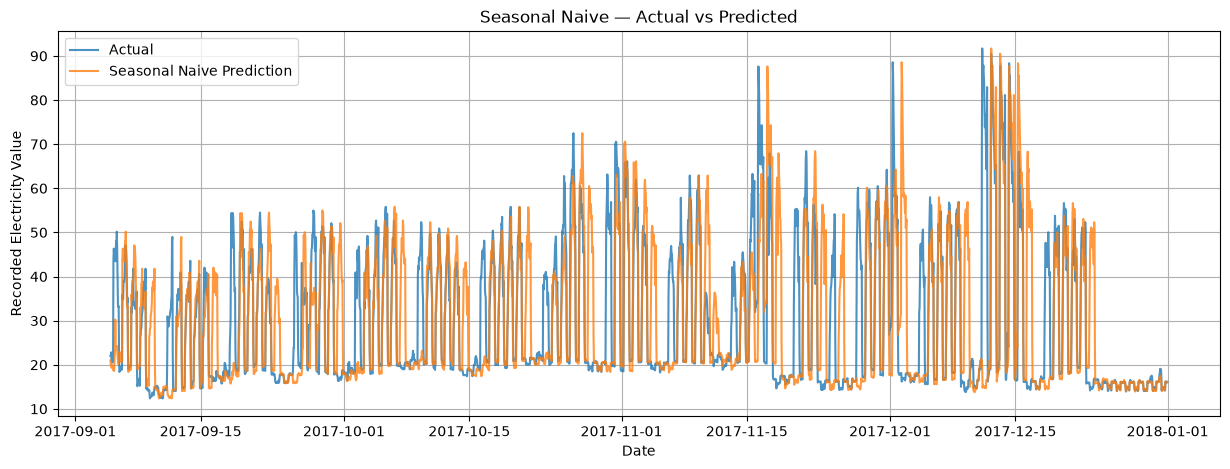

In [170]:
plt.figure(figsize=(15, 5))

plt.plot(
    actual.index,
    actual,
    label="Actual",
    alpha=0.8
)

plt.plot(
    seasonal_pred.index,
    seasonal_pred,
    label="Seasonal Naive Prediction",
    alpha=0.8
)

plt.title("Seasonal Naive — Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")

plt.legend()
plt.grid(True)
plt.show()

In [171]:
comparison = pd.DataFrame({
    "Model": ["Naive", "Seasonal Naive"],
    "MAE": [mae, seasonal_mae],
    "RMSE": [rmse, seasonal_rmse]
})

display(comparison.round(3))

,Model,MAE,RMSE
0,Naive,2.553,5.523
1,Seasonal Naive,7.521,13.694


## Comparison of Naive and Seasonal Naive Forecasting

Two baseline forecasting models were implemented to predict hourly electricity readings for Panther Office Karla.

### Model 1 — Naive Forecasting

The Naive model predicts the next hourly reading using the previous actual observation.

Mathematical representation:

Ŷ(t) = Y(t-1)

### Model 2 — Seasonal Naive Forecasting

The Seasonal Naive model predicts the next hourly reading using the observation from the same hour on the previous day.

Mathematical representation:

Ŷ(t) = Y(t-24)

### Evaluation Results

| Model | MAE | RMSE |
|---|---:|---:|
| Naive | 2.553 | 5.523 |
| Seasonal Naive | 7.521 | 13.694 |

### Interpretation

The Naive model achieved substantially lower prediction errors than the Seasonal Naive model.

The Naive model's MAE was 2.553, compared with 7.521 for Seasonal Naive. Similarly, its RMSE was 5.523, compared with 13.694.

This indicates that, during the selected testing period, the previous hour's reading provided a more reliable prediction than the same hour on the previous day.

A possible explanation is that the building's daily electricity patterns are not sufficiently stable across consecutive days. Changes in operating conditions and daily fluctuations may reduce the usefulness of historical daily repetition.

### Conclusion

The Naive model currently provides the strongest baseline forecasting performance.

Although daily seasonal patterns were identified during exploratory analysis, the Seasonal Naive model did not outperform the simpler Naive approach.

This demonstrates that identifying seasonality in historical data does not automatically mean that a seasonal forecasting model will produce better predictions.

Further models will be evaluated against these baseline results.

# Moving Average Forecasting

In [172]:
# Moving Average Forecasting

ma_3_predictions = (
    target_interpolated
    .shift(1)
    .rolling(window=3)
    .mean()
    .loc[test.index]
)

display(pd.DataFrame({
    "Actual": test.head(10),
    "Naive": naive_predictions.head(10),
    "Moving Average (3h)": ma_3_predictions.head(10)
}))

,Actual,Naive,Moving Average (3h)
timestamp,,,
2017-09-04 22:00:00,21.9642,22.8044,21.684167
2017-09-04 23:00:00,21.9642,21.9642,22.284267
2017-09-05 00:00:00,22.8044,21.9642,22.244267
2017-09-05 01:00:00,20.8840,22.8044,22.244267
2017-09-05 02:00:00,21.0040,20.8840,21.884200
2017-09-05 03:00:00,20.6440,21.0040,21.564133
2017-09-05 04:00:00,20.5240,20.6440,20.844000
2017-09-05 05:00:00,21.0040,20.5240,20.724000
2017-09-05 06:00:00,43.9285,21.0040,20.724000


In [173]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

valid_mask = target.loc[test.index].notna()

actual = target.loc[test.index][valid_mask]

ma_3_pred = ma_3_predictions[valid_mask]

ma_3_mae = mean_absolute_error(actual, ma_3_pred)

ma_3_rmse = np.sqrt(
    mean_squared_error(actual, ma_3_pred)
)

print("Moving Average (3 hours)")
print("MAE:", round(ma_3_mae, 3))
print("RMSE:", round(ma_3_rmse, 3))

Moving Average (3 hours)
MAE: 4.3
RMSE: 7.954


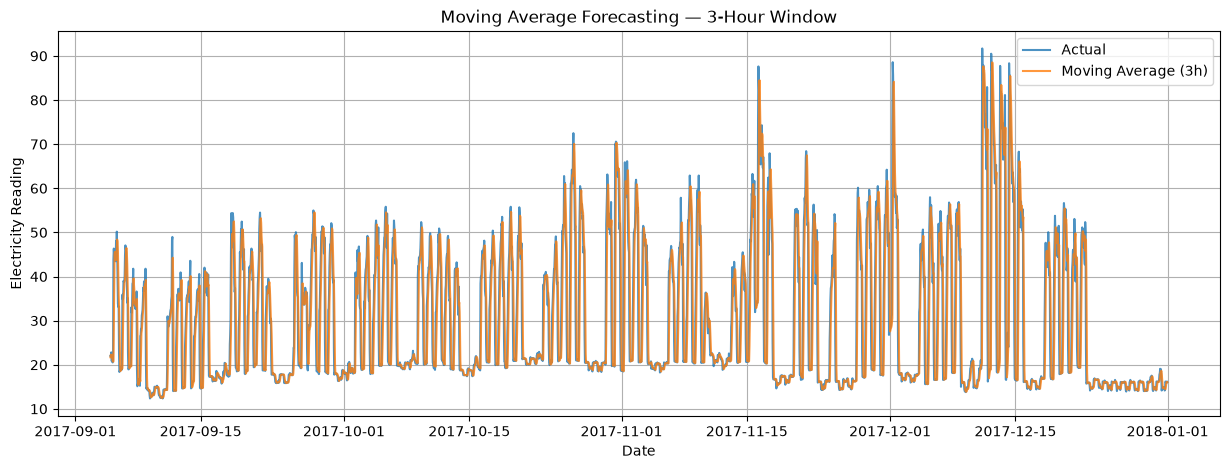

In [174]:
plt.figure(figsize=(15, 5))

plt.plot(
    actual.index,
    actual,
    label="Actual",
    alpha=0.8
)

plt.plot(
    ma_3_pred.index,
    ma_3_pred,
    label="Moving Average (3h)",
    alpha=0.8
)

plt.title("Moving Average Forecasting — 3-Hour Window")
plt.xlabel("Date")
plt.ylabel("Electricity Reading")

plt.legend()
plt.grid(True)
plt.show()

In [175]:
windows = [3, 6, 24]

ma_results = []

for window in windows:

    predictions = (
        target_interpolated
        .shift(1)
        .rolling(window=window)
        .mean()
        .loc[test.index]
    )

    predictions = predictions[valid_mask]

    mae_value = mean_absolute_error(
        actual, predictions
    )

    rmse_value = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    ma_results.append({
        "Window": window,
        "MAE": mae_value,
        "RMSE": rmse_value
    })

ma_comparison = pd.DataFrame(ma_results)

display(ma_comparison.round(3))

,Window,MAE,RMSE
0,3,4.300,7.954
1,6,6.756,10.882
2,24,10.502,13.791


## Model 3 — Moving Average Forecasting

Moving Average forecasting was implemented to investigate whether averaging multiple previous hourly electricity readings improves next-hour prediction accuracy.

Three window sizes were evaluated: 3, 6 and 24 hours.

### Evaluation Results

| Window Size | MAE | RMSE |
|---|---:|---:|
| 3 hours | 4.300 | 7.954 |
| 6 hours | 6.756 | 10.882 |
| 24 hours | 10.502 | 13.791 |

### Interpretation

The 3-hour window achieved the best performance among the three Moving Average experiments.

Increasing the window size resulted in progressively higher prediction errors. This suggests that averaging a larger number of historical observations introduced excessive smoothing and reduced the model's ability to respond to short-term changes in electricity readings.

The Moving Average models did not outperform the Naive baseline, which achieved an MAE of 2.553 and RMSE of 5.523.

### Conclusion

For this building and testing period, using the previous hourly reading provided more accurate predictions than averaging multiple historical observations.

The results demonstrate that excessive smoothing can reduce forecasting accuracy when the target series contains frequent short-term fluctuations.

The Naive model remains the best-performing baseline so far.

# Exponential Smoothing

In [176]:
def exponential_smoothing_forecast(train, test, alpha):

    # Initial smoothed value
    level = train.iloc[0]

    # Process historical training observations
    for value in train.iloc[1:]:
        level = alpha * value + (1 - alpha) * level

    predictions = []

    # Forecast each test observation
    for timestamp in test.index:

        # Predict using the previous smoothed value
        predictions.append(level)

        # Update only after the actual observation becomes available
        actual_value = target_interpolated.loc[timestamp]

        level = (
            alpha * actual_value
            + (1 - alpha) * level
        )

    return pd.Series(
        predictions,
        index=test.index
    )

In [177]:
ses_results = []

ses_predictions = {}

valid_mask = target.loc[test.index].notna()

actual = target.loc[test.index][valid_mask]

for alpha in [0.2, 0.5, 0.8]:

    predictions = exponential_smoothing_forecast(
        train,
        test,
        alpha
    )

    ses_predictions[alpha] = predictions

    predicted = predictions[valid_mask]

    mae_value = mean_absolute_error(
        actual, predicted
    )

    rmse_value = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    ses_results.append({
        "Alpha": alpha,
        "MAE": mae_value,
        "RMSE": rmse_value
    })

ses_comparison = pd.DataFrame(ses_results)

display(ses_comparison.round(3))

,Alpha,MAE,RMSE
0,0.2,7.349,10.770
1,0.5,4.078,7.322
2,0.8,2.915,5.957


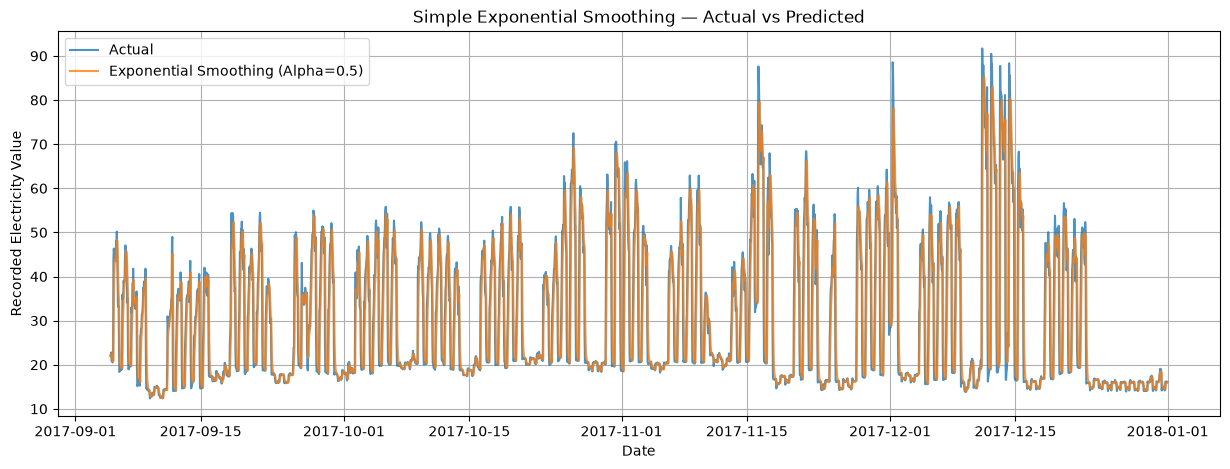

In [178]:
plt.figure(figsize=(15, 5))

plt.plot(
    actual.index,
    actual,
    label="Actual",
    alpha=0.8
)

plt.plot(
    actual.index,
    ses_predictions[0.5].loc[actual.index],
    label="Exponential Smoothing (Alpha=0.5)",
    alpha=0.8
)

plt.title("Simple Exponential Smoothing — Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")

plt.legend()
plt.grid(True)
plt.show()

## Model 4 — Simple Exponential Smoothing

Simple Exponential Smoothing (SES) was implemented to investigate whether assigning greater importance to recent electricity readings improves next-hour forecasting accuracy.

The model uses a smoothing parameter called Alpha (α), which controls the influence of the latest observation on the updated smoothed value.

Three Alpha values were evaluated: 0.2, 0.5 and 0.8.

### Evaluation Results

| Alpha | MAE | RMSE |
|---|---:|---:|
| 0.2 | 7.349 | 10.770 |
| 0.5 | 4.078 | 7.322 |
| 0.8 | 2.915 | 5.957 |

### Interpretation

Forecasting accuracy improved as Alpha increased.

Alpha = 0.8 produced the lowest errors among the three configurations. This indicates that giving greater importance to recent electricity observations was beneficial for this building and testing period.

However, SES did not outperform the Naive forecasting baseline.

The Naive model achieved an MAE of 2.553 and RMSE of 5.523, compared with 2.915 and 5.957 respectively for SES at Alpha = 0.8.

### Conclusion

The results suggest that recent electricity readings contain useful information for short-term forecasting.

A higher Alpha allows the model to respond more quickly to changes in the readings. Nevertheless, the Naive model remains the strongest baseline among the forecasting methods evaluated so far.

Further investigation using models that account for trends and seasonal behaviour is required.

# Holt's Linear Trend Method

In [179]:
def holt_forecast(train, test, alpha, beta):

    # Initialise level and trend
    level = train.iloc[0]
    trend = train.iloc[1] - train.iloc[0]

    # Process training observations
    for value in train.iloc[1:]:

        previous_level = level

        level = (
            alpha * value
            + (1 - alpha) * (level + trend)
        )

        trend = (
            beta * (level - previous_level)
            + (1 - beta) * trend
        )

    predictions = []

    # One-step-ahead testing
    for timestamp in test.index:

        # Predict next hour
        forecast = level + trend
        predictions.append(forecast)

        # Update after actual observation becomes available
        actual_value = target_interpolated.loc[timestamp]

        previous_level = level

        level = (
            alpha * actual_value
            + (1 - alpha) * (level + trend)
        )

        trend = (
            beta * (level - previous_level)
            + (1 - beta) * trend
        )

    return pd.Series(predictions, index=test.index)

In [180]:
holt_results = []
holt_predictions = {}

for alpha in [0.5, 0.8]:

    for beta in [0.1, 0.3, 0.5]:

        predictions = holt_forecast(
            train,
            test,
            alpha,
            beta
        )

        holt_predictions[(alpha, beta)] = predictions

        valid_mask = target.loc[test.index].notna()

        actual = target.loc[test.index][valid_mask]
        predicted = predictions[valid_mask]

        mae_value = mean_absolute_error(
            actual, predicted
        )

        rmse_value = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        holt_results.append({
            "Alpha": alpha,
            "Beta": beta,
            "MAE": mae_value,
            "RMSE": rmse_value
        })

holt_comparison = pd.DataFrame(holt_results)

display(holt_comparison.round(3))

,Alpha,Beta,MAE,RMSE
0,0.5,0.1,4.560,7.746
1,0.5,0.3,4.584,7.360
2,0.5,0.5,4.249,6.994
3,0.8,0.1,3.279,6.131
4,0.8,0.3,3.413,6.022
5,0.8,0.5,3.267,6.038


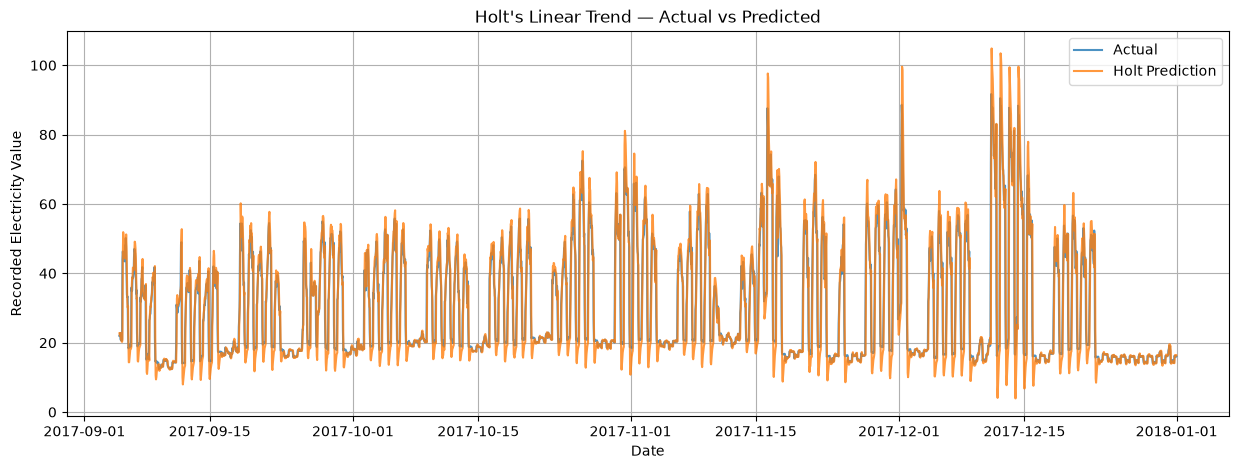

In [181]:
selected_holt = holt_predictions[(0.8, 0.3)]

plt.figure(figsize=(15, 5))

plt.plot(
    actual.index,
    actual,
    label="Actual",
    alpha=0.8
)

plt.plot(
    selected_holt.loc[actual.index].index,
    selected_holt.loc[actual.index],
    label="Holt Prediction",
    alpha=0.8
)

plt.title("Holt's Linear Trend — Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")

plt.legend()
plt.grid(True)
plt.show()

## Model 5 — Holt's Linear Trend Method

Holt's Linear Trend Method was implemented to investigate whether explicitly modelling the level and trend components improves hourly electricity forecasting accuracy.

Unlike Simple Exponential Smoothing, Holt's method maintains two components:

- Level: the estimated current value of the time series.
- Trend: the estimated direction and rate of change.

Two smoothing parameters were investigated: Alpha (α), controlling level updates, and Beta (β), controlling trend updates.

### Evaluation Results

| Alpha | Beta | MAE | RMSE |
|---|---|---:|---:|
| 0.5 | 0.1 | 4.560 | 7.746 |
| 0.5 | 0.3 | 4.584 | 7.360 |
| 0.5 | 0.5 | 4.249 | 6.994 |
| 0.8 | 0.1 | 3.279 | 6.131 |
| 0.8 | 0.3 | 3.413 | 6.022 |
| 0.8 | 0.5 | 3.267 | 6.038 |

### Interpretation

The best MAE was obtained with Alpha = 0.8 and Beta = 0.5, while the lowest RMSE was obtained with Alpha = 0.8 and Beta = 0.3.

Higher Alpha values generally produced better results, indicating that recent observations are important for estimating the current electricity-reading level.

However, Holt's method did not outperform the Naive forecasting baseline, which achieved an MAE of 2.553 and RMSE of 5.523.

### Conclusion

Explicitly modelling the trend did not improve next-hour forecasting accuracy for the selected building and testing period.

The results suggest that the previous hourly observation provides a particularly strong reference for short-term prediction.

Further investigation using models that account for both trend and recurring seasonal behaviour is warranted.

# Holt-Winters Exponential Smoothing

In [182]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=24,
    initialization_method="estimated"
)

In [183]:
hw_fitted = hw_model.fit(
    optimized=True
)

In [184]:
hw_predictions = hw_fitted.forecast(
    steps=len(test)
)

hw_predictions.index = test.index

In [185]:
valid_mask = target.loc[test.index].notna()

actual = target.loc[test.index][valid_mask]

predicted = hw_predictions[valid_mask]

hw_mae = mean_absolute_error(
    actual, predicted
)

hw_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("Holt-Winters Results")
print("--------------------")
print("MAE:", round(hw_mae, 3))
print("RMSE:", round(hw_rmse, 3))

Holt-Winters Results
--------------------
MAE: 11.03
RMSE: 13.971


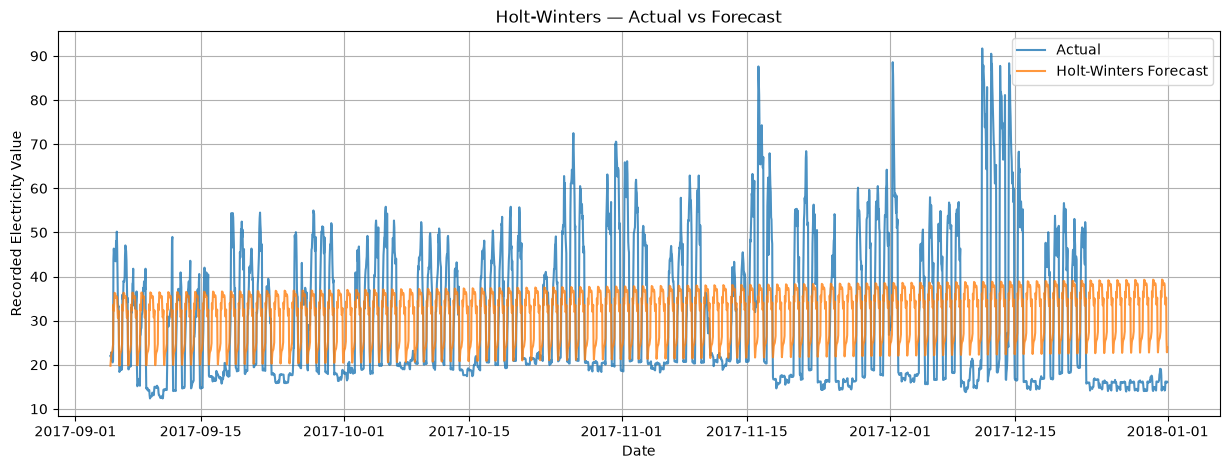

In [186]:
plt.figure(figsize=(15, 5))

plt.plot(
    actual.index,
    actual,
    label="Actual",
    alpha=0.8
)

plt.plot(
    predicted.index,
    predicted,
    label="Holt-Winters Forecast",
    alpha=0.8
)

plt.title("Holt-Winters — Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Recorded Electricity Value")

plt.legend()
plt.grid(True)
plt.show()

Holt-Winters Exponential Smoothing was applied using additive trend and daily seasonality (24-hour period). It achieved an MAE of 11.030 and RMSE of 13.971. Its performance was weaker than the Naive model. However, Holt-Winters was evaluated using a fixed multi-step forecast, whereas earlier models used rolling one-step-ahead predictions. A consistent evaluation strategy is required before drawing a definitive comparison.

In [187]:
print("Train:", train.shape)
print("Test:", test.shape)

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

print("Original missing values:", target.isna().sum())
print("Interpolated missing values:", target_interpolated.isna().sum())

Train: (11332,)
Test: (2834,)
Training period: 2016-05-20 18:00:00 to 2017-09-04 21:00:00
Testing period: 2017-09-04 22:00:00 to 2017-12-31 23:00:00
Original missing values: 11
Interpolated missing values: 0


In [188]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_forecast(actual, predicted, original_target):

    valid_mask = original_target.loc[actual.index].notna()

    actual_valid = actual[valid_mask]
    predicted_valid = predicted[valid_mask]

    mae = mean_absolute_error(actual_valid, predicted_valid)
    rmse = np.sqrt(mean_squared_error(actual_valid, predicted_valid))

    return mae, rmse

In [189]:
# Rolling one-step-ahead Naive forecast
naive_predictions = target_interpolated.shift(1).loc[test.index]

# Evaluate using the common function
naive_mae, naive_rmse = evaluate_forecast(
    test,
    naive_predictions,
    target
)

print("Naive Model Results")
print("-------------------")
print(f"MAE: {naive_mae:.3f}")
print(f"RMSE: {naive_rmse:.3f}")

Naive Model Results
-------------------
MAE: 2.553
RMSE: 5.523


In [190]:
# Predict using the reading from 24 hours earlier
seasonal_naive_predictions = (
    target_interpolated.shift(24).loc[test.index]
)

# Evaluate
seasonal_mae, seasonal_rmse = evaluate_forecast(
    test,
    seasonal_naive_predictions,
    target
)

print("Seasonal Naive Results")
print("----------------------")
print(f"MAE: {seasonal_mae:.3f}")
print(f"RMSE: {seasonal_rmse:.3f}")

Seasonal Naive Results
----------------------
MAE: 7.521
RMSE: 13.694


In [191]:
naive_predictions = target_interpolated.shift(1).loc[test.index]

naive_mae, naive_rmse = evaluate_forecast(
    test, naive_predictions, target
)

In [192]:
seasonal_naive_predictions = (
    target_interpolated.shift(24).loc[test.index]
)

seasonal_mae, seasonal_rmse = evaluate_forecast(
    test, seasonal_naive_predictions, target
)

In [193]:
moving_average_results = {}

for window in [3, 6, 24]:

    predictions = (
        target_interpolated
        .shift(1)
        .rolling(window=window)
        .mean()
        .loc[test.index]
    )

    mae, rmse = evaluate_forecast(
        test, predictions, target
    )

    moving_average_results[window] = {
        "MAE": mae,
        "RMSE": rmse
    }

In [194]:
def ses_rolling_forecast(train, test, alpha):

    level = train.iloc[0]

    # Initialise using training observations
    for value in train.iloc[1:]:
        level = alpha * value + (1 - alpha) * level

    predictions = []

    # Rolling one-step-ahead forecasting
    for timestamp in test.index:

        predictions.append(level)

        actual_value = target_interpolated.loc[timestamp]

        level = (
            alpha * actual_value
            + (1 - alpha) * level
        )

    return pd.Series(predictions, index=test.index)


ses_predictions = ses_rolling_forecast(
    train, test, alpha=0.8
)

ses_mae, ses_rmse = evaluate_forecast(
    test, ses_predictions, target
)

In [195]:
def holt_rolling_forecast(train, test, alpha, beta):

    level = train.iloc[0]
    trend = train.iloc[1] - train.iloc[0]

    # Initialise using training observations
    for value in train.iloc[1:]:

        previous_level = level

        level = (
            alpha * value
            + (1 - alpha) * (level + trend)
        )

        trend = (
            beta * (level - previous_level)
            + (1 - beta) * trend
        )

    predictions = []

    # Rolling one-step-ahead forecasting
    for timestamp in test.index:

        forecast = level + trend
        predictions.append(forecast)

        actual_value = target_interpolated.loc[timestamp]

        previous_level = level

        level = (
            alpha * actual_value
            + (1 - alpha) * (level + trend)
        )

        trend = (
            beta * (level - previous_level)
            + (1 - beta) * trend
        )

    return pd.Series(predictions, index=test.index)


holt_predictions = holt_rolling_forecast(
    train, test,
    alpha=0.8,
    beta=0.5
)

holt_mae, holt_rmse = evaluate_forecast(
    test, holt_predictions, target
)

In [197]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=24,
    initialization_method="estimated"
)

hw_result = hw_model.fit(optimized=True)

In [198]:
# Extract fitted smoothing parameters
alpha = hw_result.params["smoothing_level"]
beta = hw_result.params["smoothing_trend"]
gamma = hw_result.params["smoothing_seasonal"]

# Extract final training states
level = hw_result.level.iloc[-1]
trend = hw_result.trend.iloc[-1]

# Last 24 seasonal states
seasonal_cycle = hw_result.season.iloc[-24:].to_numpy().copy()

hw_predictions_list = []

# Next seasonal position
season_index = 0

for timestamp in test.index:

    # 1. Forecast the next hour
    seasonal_value = seasonal_cycle[season_index]

    forecast = level + trend + seasonal_value
    hw_predictions_list.append(forecast)

    # 2. Observe actual reading
    actual_value = target_interpolated.loc[timestamp]

    # 3. Update level
    previous_level = level

    level = (
        alpha * (actual_value - seasonal_value)
        + (1 - alpha) * (level + trend)
    )

    # 4. Update trend
    trend = (
        beta * (level - previous_level)
        + (1 - beta) * trend
    )

    # 5. Update seasonal component
    updated_season = (
        gamma * (actual_value - level)
        + (1 - gamma) * seasonal_value
    )

    seasonal_cycle[season_index] = updated_season

    # Move to next seasonal position
    season_index = (season_index + 1) % 24


# Convert predictions into a Series
hw_predictions = pd.Series(
    hw_predictions_list,
    index=test.index
)

# Evaluate
hw_mae, hw_rmse = evaluate_forecast(
    test,
    hw_predictions,
    target
)

print("Rolling Holt-Winters Results")
print("----------------------------")
print(f"MAE: {hw_mae:.3f}")
print(f"RMSE: {hw_rmse:.3f}")

Rolling Holt-Winters Results
----------------------------
MAE: 2.461
RMSE: 4.377


In [199]:
print("Statsmodels version:", __import__("statsmodels").__version__)

print("Available model parameters:")
print(hw_result.params)

print("\nAvailable model attributes:")
print([attr for attr in dir(hw_result)
       if attr in ["level", "trend", "season", "seasonal"]])

Statsmodels version: 0.15.0
Available model parameters:
{'smoothing_level': np.float64(0.9925580485050448), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.00744195149495519), 'damping_trend': nan, 'initial_level': np.float64(19.888625837959683), 'initial_trend': np.float64(0.0010727299134440484), 'initial_seasons': array([ 1.3062253 ,  0.61202137,  0.51639299, -6.27264758, -8.51098569,
       -7.7218641 , -7.52779047, -8.14083478, -6.42597553, -4.66419533,
       -4.31729011, -4.8528333 ,  2.05088622,  2.44761148,  4.13136385,
        6.05998205,  5.82023812,  6.19732309,  5.57344611,  5.38627899,
        5.58943835,  5.28691364,  4.70901243,  3.06057885]), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}

Available model attributes:
['level', 'season', 'trend']


In [200]:
results = {
    "Naive": {
        "MAE": naive_mae,
        "RMSE": naive_rmse
    },

    "Seasonal Naive": {
        "MAE": seasonal_mae,
        "RMSE": seasonal_rmse
    },

    "Moving Average (3h)": moving_average_results[3],
    "Moving Average (6h)": moving_average_results[6],
    "Moving Average (24h)": moving_average_results[24],

    "SES (alpha=0.8)": {
        "MAE": ses_mae,
        "RMSE": ses_rmse
    },

    "Holt (0.8, 0.5)": {
        "MAE": holt_mae,
        "RMSE": holt_rmse
    },

    "Holt-Winters": {
        "MAE": hw_mae,
        "RMSE": hw_rmse
    }
}

comparison_df = pd.DataFrame(results).T

comparison_df = comparison_df.sort_values("MAE")

display(comparison_df.round(3))

,MAE,RMSE
Holt-Winters,2.461,4.377
Naive,2.553,5.523
SES (alpha=0.8),2.915,5.957
"Holt (0.8, 0.5)",3.267,6.038
Moving Average (3h),4.300,7.954
Moving Average (6h),6.756,10.882
Seasonal Naive,7.521,13.694
Moving Average (24h),10.502,13.791


### Baseline Forecasting Model Evaluation

Eight forecasting configurations were evaluated using a rolling one-step-ahead forecasting strategy on the Panther_office_Karla electricity meter.

Holt-Winters Exponential Smoothing achieved the best performance, with an MAE of 2.461 and RMSE of 4.377. The Naive model followed closely, achieving an MAE of 2.553 and RMSE of 5.523.

The results indicate that incorporating level, trend and daily seasonal components can improve short-term forecasting accuracy. However, the relatively small MAE improvement over the Naive model highlights the strong predictive value of the immediately preceding electricity reading.

Seasonal Naive and longer moving-average windows performed considerably worse, suggesting that daily repetition alone does not adequately represent the meter's consumption dynamics.

Holt-Winters is selected as the current best-performing baseline candidate. Further evaluation using statistical and machine-learning forecasting models is required before selecting a final model.

# ARIMA — Autoregressive Integrated Moving Average

In [201]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -7.276292194201085
p-value: 1.5413453247200437e-10
Critical Values:
1%: -3.4309292921170726
5%: -2.8617960158801705
10%: -2.566906272144382


### Augmented Dickey-Fuller Stationarity Test

The ADF test was performed on the training dataset of the Panther_office_Karla electricity meter.

The test produced an ADF statistic of -7.2763 and a p-value of 1.54 × 10⁻¹⁰. Since the p-value is considerably below the 0.05 significance threshold, the null hypothesis of a unit root was rejected.

The training series therefore shows strong evidence of stationarity according to the ADF test.

Based on this result, the initial ARIMA differencing parameter is selected as d = 0. Further examination of autocorrelation and seasonal patterns will help determine the remaining model parameters.

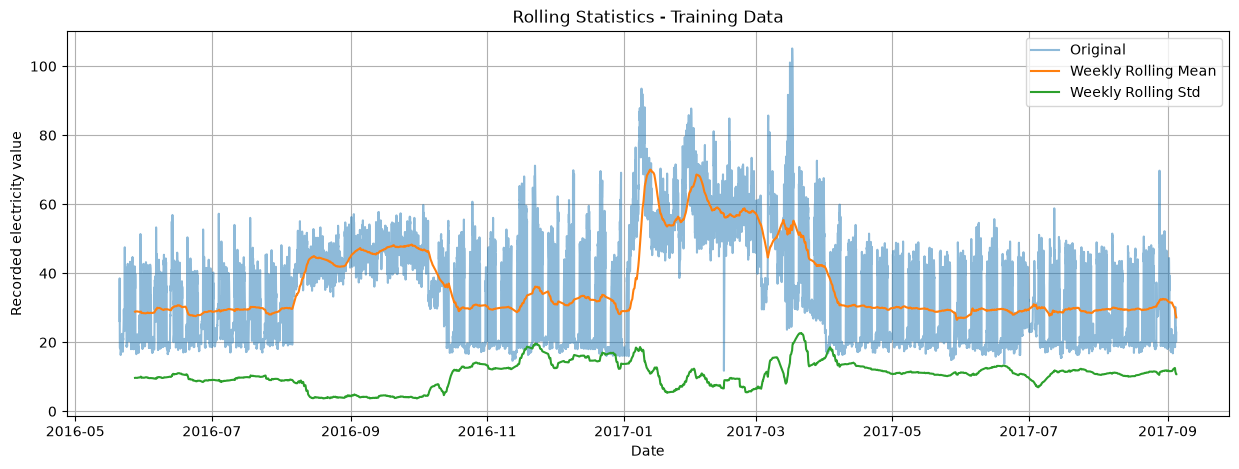

In [202]:
import matplotlib.pyplot as plt

rolling_mean = train.rolling(window=168).mean()
rolling_std = train.rolling(window=168).std()

plt.figure(figsize=(15, 5))

plt.plot(train, label="Original", alpha=0.5)
plt.plot(rolling_mean, label="Weekly Rolling Mean")
plt.plot(rolling_std, label="Weekly Rolling Std")

plt.title("Rolling Statistics - Training Data")
plt.xlabel("Date")
plt.ylabel("Recorded electricity value")
plt.legend()
plt.grid(True)
plt.show()

In [203]:
monthly_stats = train.resample("ME").agg(
    ["mean", "std"]
)

display(monthly_stats)

,mean,std
timestamp,,
2016-05-31,27.964504,9.541476
2016-06-30,29.314655,9.710765
2016-07-31,29.064800,9.402710
2016-08-31,41.698690,6.890537
2016-09-30,47.163432,4.202670
2016-10-31,33.665043,12.110085
2016-11-30,32.279061,15.426690
2016-12-31,31.688697,15.447360
2017-01-31,57.946826,15.004943


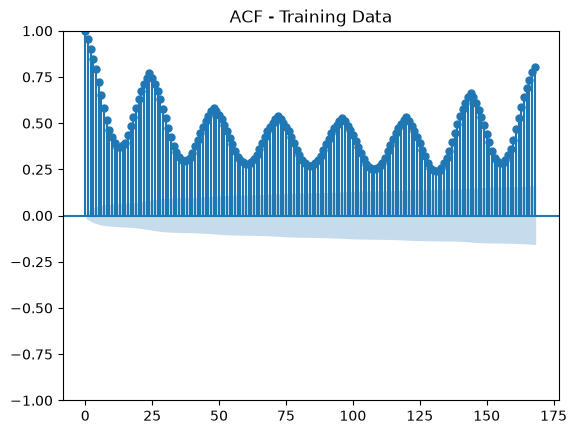

In [204]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(train, lags=168)

plt.title("ACF - Training Data")
plt.show()

Interpretation: 

The rolling mean and variance are not constant throughout the training period.

electricity readings have a strong daily autocorrelation pattern

rolling statistics suggest that the series has changing levels and variability

ADF evidence against a unit root, but insufficient evidence that the original series is stationary in all relevant statistical properties.

We should not automatically conclude that d = 0.

# First-order differencing

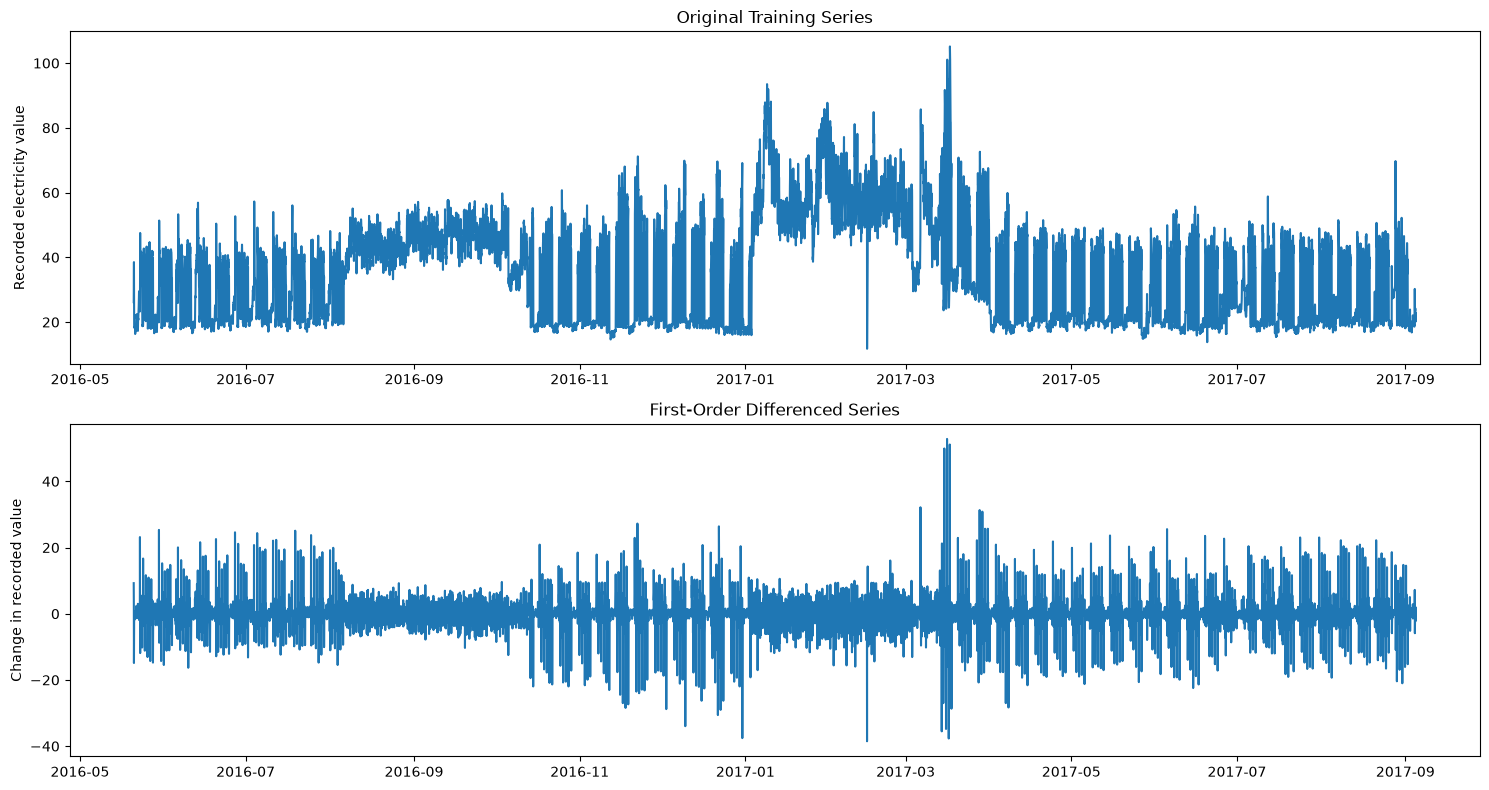

In [205]:
# First-order differencing
train_diff = train.diff().dropna()

# Plot original and differenced series
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(train)
axes[0].set_title("Original Training Series")
axes[0].set_ylabel("Recorded electricity value")

axes[1].plot(train_diff)
axes[1].set_title("First-Order Differenced Series")
axes[1].set_ylabel("Change in recorded value")

plt.tight_layout()
plt.show()

In [206]:
adf_diff = adfuller(train_diff)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

ADF Statistic: -22.93381425024471
p-value: 0.0


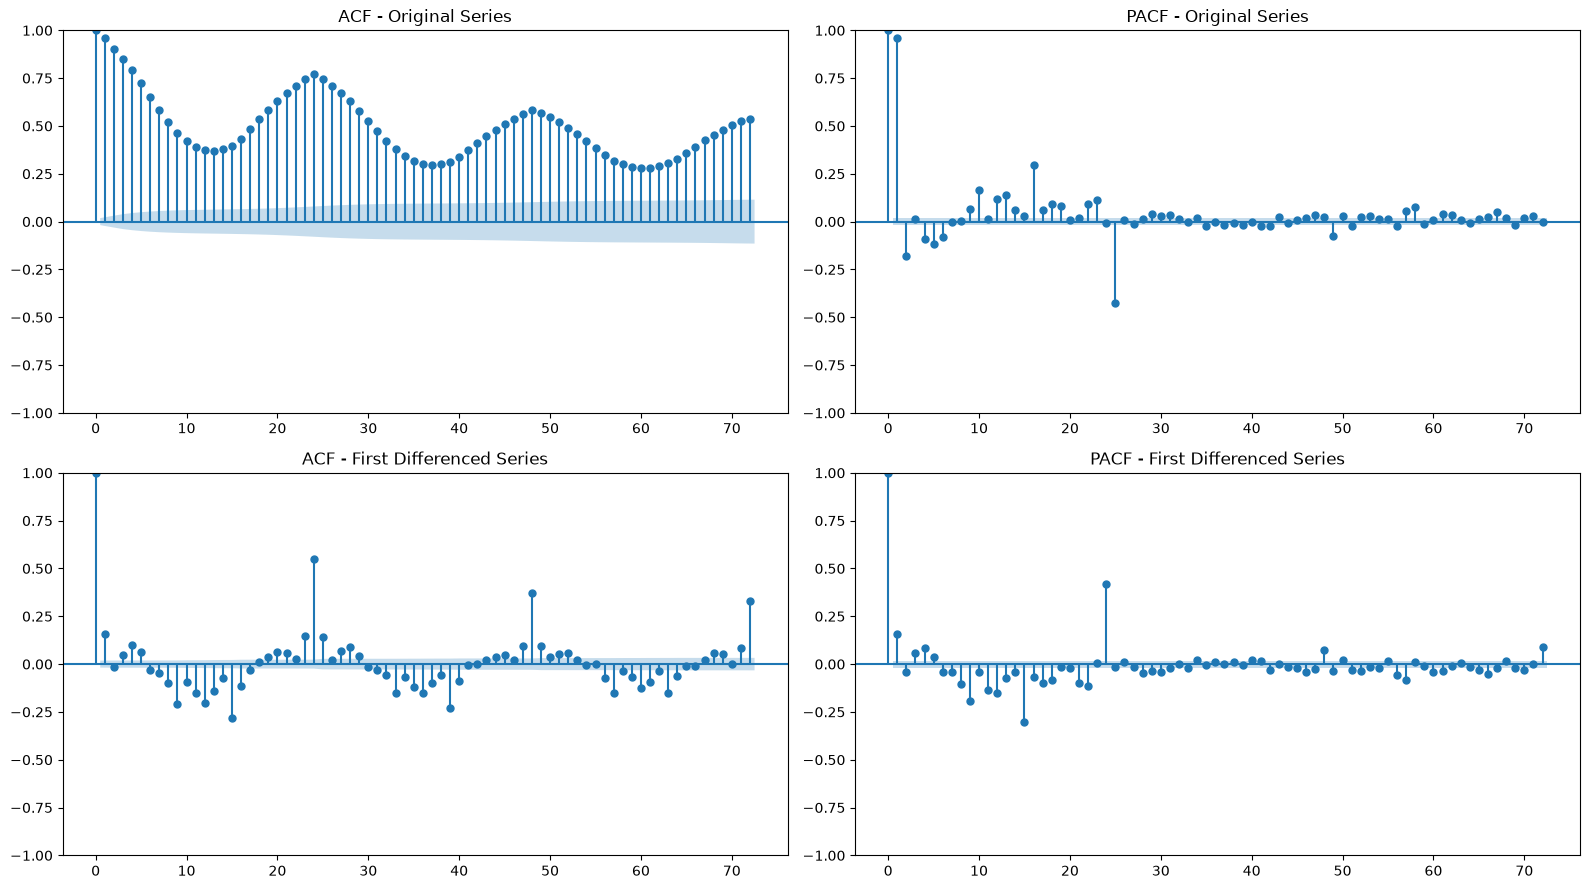

In [207]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# Original series
plot_acf(train, lags=72, ax=axes[0, 0])
axes[0, 0].set_title("ACF - Original Series")

plot_pacf(train, lags=72, ax=axes[0, 1], method="ywm")
axes[0, 1].set_title("PACF - Original Series")

# Differenced series
plot_acf(train_diff, lags=72, ax=axes[1, 0])
axes[1, 0].set_title("ACF - First Differenced Series")

plot_pacf(train_diff, lags=72, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF - First Differenced Series")

plt.tight_layout()
plt.show()

1. Original series — ACF

Look at the top-left graph.

Interpretation:
1. The series has strong dependence on previous observations.
2. Daily seasonality is clearly visible.
3. The slow ACF decay suggests persistent temporal structure.
This supports our earlier observation that the series has strong daily patterns.

2. Original series — PACF

Look at the top-right graph.

It suggests that the immediately preceding observation contains substantial predictive information.

Remember our Naive model? It performed very well. This PACF structure helps explain why.

3. Differenced series — ACF

Now look at the bottom-left graph.

Interesting observations:
- The correlations decay much faster than in the original ACF.
- There are negative correlations at several short lags.
- Strong positive peaks remain around 24, 48 and 72.
Interpretation:

Differencing has reduced the slow correlation structure, but the daily seasonal pattern remains.

This is an important clue: ordinary differencing does not eliminate daily seasonality.

4. Differenced series — PACF

The bottom-right graph shows:
- A noticeable lag-1 relationship.
- Several smaller negative correlations.
- A strong seasonal spike around lag 24.
This suggests that seasonal behaviour may need to be explicitly modelled

In [208]:
from statsmodels.tsa.arima.model import ARIMA

arima_candidates = {
    "ARIMA(1,0,0)": (1, 0, 0),
    "ARIMA(2,0,0)": (2, 0, 0),
    "ARIMA(1,0,1)": (1, 0, 1),
    "ARIMA(1,1,0)": (1, 1, 0),
    "ARIMA(1,1,1)": (1, 1, 1)
}

arima_results = []

for name, order in arima_candidates.items():

    model = ARIMA(train, order=order)
    fitted_model = model.fit()

    arima_results.append({
        "Model": name,
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic
    })

arima_comparison = pd.DataFrame(arima_results)

display(
    arima_comparison.sort_values("AIC").round(3)
)

,Model,AIC,BIC
2,"ARIMA(1,0,1)",65590.051,65619.393
1,"ARIMA(2,0,0)",65596.045,65625.386
4,"ARIMA(1,1,1)",65895.125,65917.131
3,"ARIMA(1,1,0)",65922.130,65936.800
0,"ARIMA(1,0,0)",65979.736,66001.742


In [209]:
from statsmodels.tsa.arima.model import ARIMA

# Fit a fresh model
arima_model = ARIMA(
    train,
    order=(1, 0, 1)
)

arima_fitted = arima_model.fit()

arima_predictions = []

for timestamp in test.index:

    # Predict next hour
    forecast = arima_fitted.forecast(steps=1).iloc[0]
    arima_predictions.append(forecast)

    # Get actual observation
    actual_value = target_interpolated.loc[timestamp]

    # Preserve the original Series name
    new_observation = pd.Series(
        [actual_value],
        index=pd.DatetimeIndex([timestamp]),
        name=train.name
    )

    # Update model
    arima_fitted = arima_fitted.append(
        new_observation,
        refit=False
    )

# Convert predictions to Series
arima_predictions = pd.Series(
    arima_predictions,
    index=test.index
)

# Evaluate
arima_mae, arima_rmse = evaluate_forecast(
    test,
    arima_predictions,
    target
)

print("ARIMA(1,0,1) Results")
print("--------------------")
print(f"MAE: {arima_mae:.3f}")
print(f"RMSE: {arima_rmse:.3f}")

ARIMA(1,0,1) Results
--------------------
MAE: 2.657
RMSE: 5.224


In [210]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

sarima_candidates = {
    "SARIMA_1": (1, 0, 1, 24),
    "SARIMA_2": (1, 1, 0, 24),
    "SARIMA_3": (0, 1, 1, 24)
}

sarima_results = []

for name, seasonal_order in sarima_candidates.items():

    print(f"Training {name}...")

    model = SARIMAX(
        train,
        order=(1, 0, 1),
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False)

    sarima_results.append({
        "Model": name,
        "Seasonal Order": seasonal_order,
        "AIC": fitted.aic,
        "BIC": fitted.bic
    })

sarima_comparison = pd.DataFrame(sarima_results)

display(
    sarima_comparison
    .sort_values("AIC")
    .reset_index(drop=True)
    .round(3)
)

Training SARIMA_1...
Training SARIMA_2...
Training SARIMA_3...


,Model,Seasonal Order,AIC,BIC
0,SARIMA_3,"(0, 1, 1, 24)",60077.714,60107.038
1,SARIMA_1,"(1, 0, 1, 24)",60181.855,60218.520
2,SARIMA_2,"(1, 1, 0, 24)",63094.793,63124.117


In [212]:
# Use the first 7 days of the test dataset
sarima_test_small = test.iloc[:168]

print("Test observations:", len(sarima_test_small))
print("Start:", sarima_test_small.index[0])
print("End:", sarima_test_small.index[-1])

Test observations: 168
Start: 2017-09-04 22:00:00
End: 2017-09-11 21:00:00


In [213]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fitted = sarima_model.fit(disp=False)

print(sarima_fitted.summary())

                                     SARIMAX Results                                      
Dep. Variable:               Panther_office_Karla   No. Observations:                11332
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -30034.857
Date:                            Sun, 15 Nov 2026   AIC                          60077.714
Time:                                    00:31:18   BIC                          60107.038
Sample:                                05-20-2016   HQIC                         60087.581
                                     - 09-04-2017                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9277      0.003    278.017      0.000       0.921       0.934
ma.L1          0.1367      0.007   

In [214]:
sarima_predictions_list = []

for timestamp in sarima_test_small.index:

    # Predict the next hour
    forecast = sarima_fitted.forecast(steps=1).iloc[0]
    sarima_predictions_list.append(forecast)

    # Reveal the actual observation
    actual_value = target_interpolated.loc[timestamp]

    new_observation = pd.Series(
        [actual_value],
        index=pd.DatetimeIndex([timestamp]),
        name=train.name
    )

    # Update model without refitting parameters
    sarima_fitted = sarima_fitted.append(
        new_observation,
        refit=False
    )

sarima_predictions_small = pd.Series(
    sarima_predictions_list,
    index=sarima_test_small.index
)

print("Forecast completed:", len(sarima_predictions_small))

Forecast completed: 168


In [215]:
sarima_mae_small, sarima_rmse_small = evaluate_forecast(
    sarima_test_small,
    sarima_predictions_small,
    target
)

print(f"SARIMA MAE:  {sarima_mae_small:.3f}")
print(f"SARIMA RMSE: {sarima_rmse_small:.3f}")

SARIMA MAE:  1.890
SARIMA RMSE: 3.351


In [216]:
hw_predictions_small = hw_predictions.loc[sarima_test_small.index]

hw_mae_small, hw_rmse_small = evaluate_forecast(
    sarima_test_small,
    hw_predictions_small,
    target
)

print(f"Holt-Winters MAE:  {hw_mae_small:.3f}")
print(f"Holt-Winters RMSE: {hw_rmse_small:.3f}")

Holt-Winters MAE:  1.972
Holt-Winters RMSE: 3.383


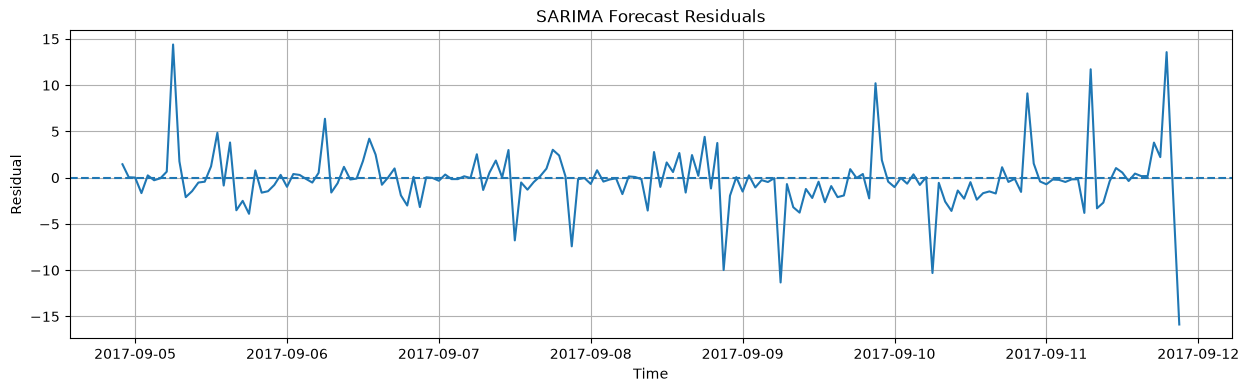

In [217]:
import matplotlib.pyplot as plt

sarima_residuals = (
    sarima_test_small - sarima_predictions_small
)

plt.figure(figsize=(15, 4))
plt.plot(sarima_residuals)
plt.axhline(0, linestyle="--")
plt.title("SARIMA Forecast Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

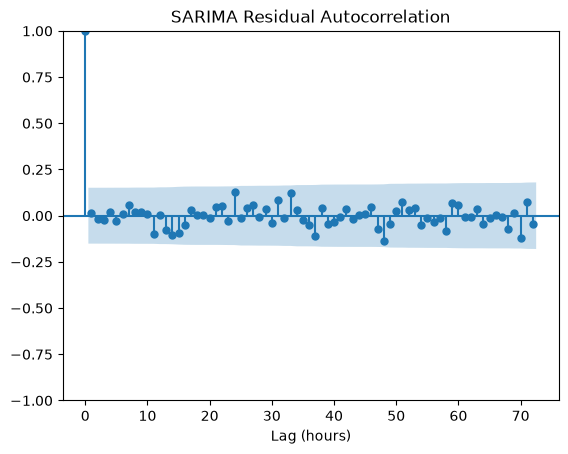

In [218]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(sarima_residuals, lags=72)
plt.title("SARIMA Residual Autocorrelation")
plt.xlabel("Lag (hours)")
plt.show()

The residual autocorrelation analysis indicates that most autocorrelation coefficients lie within the approximate 95% confidence bounds. This suggests that the SARIMA model has captured most of the linear temporal dependencies in the evaluated period. However, occasional large residuals indicate that sudden variations in electricity demand remain difficult to predict.

# save models

In [219]:
import pickle
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

models = {
    "holt_winters": hw_result,
    "arima": arima_fitted,
    "sarima": sarima_fitted
}

for name, model in models.items():

    with open(MODEL_DIR / f"{name}.pkl", "wb") as file:
        pickle.dump(model, file)

    print(f"Saved: {name}")

Saved: holt_winters
Saved: arima
Saved: sarima


In [220]:
from pathlib import Path

# Create project directories relative to the notebook's working directory
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"
FORECAST_DIR = RESULT_DIR / "forecasts"

for folder in [DATA_DIR, MODEL_DIR, RESULT_DIR, FORECAST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created:")
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)
print("Forecasts:", FORECAST_DIR)

Project folders created:
Models: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI\models
Results: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI\results
Forecasts: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI\results\forecasts


In [221]:
# Save processed datasets
target.to_frame(name="electricity").to_pickle(
    DATA_DIR / "target_original.pkl"
)

target_interpolated.to_frame(name="electricity").to_pickle(
    DATA_DIR / "target_interpolated.pkl"
)

train.to_frame(name="electricity").to_pickle(
    DATA_DIR / "train.pkl"
)

test.to_frame(name="electricity").to_pickle(
    DATA_DIR / "test.pkl"
)

print("Datasets saved successfully!")

Datasets saved successfully!


In [222]:
import pickle

models_to_save = {
    "holt_winters": hw_result,
    "arima_updated": arima_fitted,
    "sarima_updated_7day": sarima_fitted
}

for name, model in models_to_save.items():

    model_path = MODEL_DIR / f"{name}.pkl"

    with open(model_path, "wb") as file:
        pickle.dump(model, file)

    print(f"Saved: {model_path.name}")

Saved: holt_winters.pkl
Saved: arima_updated.pkl
Saved: sarima_updated_7day.pkl


In [223]:
# Combine available forecast predictions
forecast_results = pd.DataFrame({
    "actual": test,
    "naive": target_interpolated.shift(1).loc[test.index],
    "seasonal_naive": target_interpolated.shift(24).loc[test.index],
    "holt_winters": hw_predictions,
    "arima": arima_predictions
})

forecast_results.to_csv(
    FORECAST_DIR / "statistical_forecasts.csv"
)

# Save the 7-day SARIMA experiment separately
sarima_results = pd.DataFrame({
    "actual": sarima_test_small,
    "predicted": sarima_predictions_small
})

sarima_results.to_csv(
    FORECAST_DIR / "sarima_7day_forecasts.csv"
)

print("Forecast results saved successfully!")

Forecast results saved successfully!


In [224]:
comparison = []

def add_model_result(name, actual, predicted, original_target, evaluation):
    mae, rmse = evaluate_forecast(
        actual,
        predicted,
        original_target
    )

    comparison.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Evaluation": evaluation
    })


# Full-test models
add_model_result(
    "Naive", test,
    target_interpolated.shift(1).loc[test.index],
    target, "Full test"
)

add_model_result(
    "Seasonal Naive", test,
    target_interpolated.shift(24).loc[test.index],
    target, "Full test"
)

add_model_result(
    "Holt-Winters", test,
    hw_predictions, target, "Full test"
)

add_model_result(
    "ARIMA", test,
    arima_predictions, target, "Full test"
)


# Seven-day comparison
add_model_result(
    "Holt-Winters", sarima_test_small,
    hw_predictions_small, target, "7-day test"
)

add_model_result(
    "SARIMA", sarima_test_small,
    sarima_predictions_small, target, "7-day test"
)


# Create and save comparison
comparison_df = pd.DataFrame(comparison)

comparison_df.to_csv(
    RESULT_DIR / "model_comparison.csv",
    index=False
)

display(comparison_df)

,Model,MAE,RMSE,Evaluation
0,Naive,2.552842,5.523084,Full test
1,Seasonal Naive,7.520675,13.694406,Full test
2,Holt-Winters,2.460558,4.377012,Full test
3,ARIMA,2.656780,5.223778,Full test
4,Holt-Winters,1.972379,3.382706,7-day test
5,SARIMA,1.889712,3.351433,7-day test


In [225]:
comparison_df.to_csv(
    RESULT_DIR / "model_comparison.csv",
    index=False
)

print("Saved:", RESULT_DIR / "model_comparison.csv")

Saved: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI\results\model_comparison.csv


# for loading

In [ ]:
import pickle
import pandas as pd

# Load datasets
target = pd.read_pickle(DATA_DIR / "target_original.pkl")["electricity"]
target_interpolated = pd.read_pickle(DATA_DIR / "target_interpolated.pkl")["electricity"]

train = pd.read_pickle(DATA_DIR / "train.pkl")["electricity"]
test = pd.read_pickle(DATA_DIR / "test.pkl")["electricity"]

# Load fitted models
with open(MODEL_DIR / "holt_winters.pkl", "rb") as file:
    hw_result = pickle.load(file)

print("Datasets and Holt-Winters model restored!")